# 04 | KAIST: FM51 vs LI-Init vs local LM refinement

**Aim:** compare correction of **small rotations (0–45°)** across **ten non-overlapping 60-second physical segments** on held-out KAIST Urban38/Urban39. Each approach starts from the **same left LiDAR rotation** and sees consecutive 5-second measurements. Each angle is applied about a deterministic 3D axis, one axis per physical start. **Only left LiDAR rotation is updated and scored.**

Methods:

- **FM51**: existing three-sensor checkpoint, 16-step midpoint integration, one update per 5-second window.
- **LI-Init joint**: current local gyro-angular-velocity optimizer from notebook 02, warm-started every window; coarse time correlation, gyro bias and clock offset are nuisance states. **Not the cold-start global LI-Init pipeline.**
- **Motion LM (gyro + two LiDARs)**: the new `baselines.motion_refinement` solver, initialized by the same rotation. Bias and time are **fixed to the configured initial values by default**, fixed right-LiDAR extrinsics and left LiDAR lever arm are provided, with robust gyro preintegration and two-LiDAR SE(3) consistency factors.

Two **expanding-time** protocols match notebook 02: (A) optimize only each new 5-second interval; (B) at each 5-second time, reoptimize all measurements observed since the rollout began, culminating in a 60-second problem. FM trajectories are identical in both protocols. **Timing caveat:** the numerical inputs preserve notebook 02’s explicit +0.35 s future IMU padding, and LM also has +0.20 s right-LiDAR guard data, so the numerical branches are *not strictly zero-lookahead*. The expanding window itself never uses later full windows at an earlier step.

**Key asymmetries:** FM and LM use one IMU + two LiDAR odometries; LI-Init uses one IMU + left LiDAR. LM receives fixed right-LiDAR calibration and both lever arms; FM receives nominal fixed states for IMU/right LiDAR. LI-Init estimates time/bias, while LM defaults to holding them fixed (tunable). Numeric solvers receive explicit IMU padding for offset handling, while FM uses native 5-second network windows. The nominal left LiDAR rotation is used **only** to construct test perturbations and compute errors, not passed to solvers as a target.

This notebook records per-step SO(3) error, solve acceptance, observable rank, LM iterations, measured per-update latency, cumulative latency, and outputs CSV. Timing excludes disk I/O and window extraction, includes model tokenization and numerical solver internals, with CUDA synchronization around FM.

## 1. Imports and project root

In [1]:
from pathlib import Path
from dataclasses import replace
from time import perf_counter
import gc
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from tqdm.auto import tqdm
from scipy.spatial.transform import Rotation as SciRotation
from scipy.integrate import trapezoid
from IPython.display import display

ROOT = Path.cwd()
for candidate in (ROOT, *ROOT.parents):
    if (candidate / "src" / "obscalib").is_dir() and (candidate / "src" / "baselines").is_dir():
        ROOT = candidate
        break
else:
    raise FileNotFoundError("Run this notebook in nn-obs-calib; src/obscalib and src/baselines are required.")
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from kaist_dataset.dataset import KAISTCalibrationDataset, KAISTRigCalibration, build_kaist_sequence_specs
from kaist_dataset.imu import load_imus
from kaist_dataset.lidar import load_lidar_relative_poses
from obscalib.config import (WindowingConfig, TransformerConfig, CalibrationPoolerConfig, MLPConfig,
                             PooledCalibrationHeadConfig, PooledCalibrationModelConfig, PooledCalibrationFlowConfig,
                             CalibrationFlowIntegratorConfig)
from obscalib.data.collation import collate_windows
from obscalib.data.device import window_batch_to
from obscalib.calibration.state import CalibrationState
from obscalib.calibration.context import calibration_state_to_context
from obscalib.geometry.lie import so3_exp
from obscalib.geometry.processing import GeometryProcessor
from obscalib.tokenization.tokenizer import Tokenizer
from obscalib.models.pooled_calibration_flow_model import PooledCalibrationFlowModel
from obscalib.training.checkpoint import load_training_checkpoint
from baselines.li_init import LIInitConfig, lidar_increments_to_motion
from baselines.li_init.adapters import (kaist_records_to_li_init, slice_li_init_window,
                                         reference_from_body_calibrations, make_lidar_increments)
from baselines.motion_refinement import MotionRefinementConfig, MotionRefinementCalibrator
from baselines.li_init.rotation import solve_Rot_bias_gyro
from baselines.li_init.temporal import xcorr_temporal_init
from baselines.li_init.benchmark import rotation_error_degrees

print("Root:", ROOT, "| Torch:", torch.__version__)


Root: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib | Torch: 2.7.1+cu126


## 2. Experiment configuration

In [2]:
# Physical paths from KAIST notebooks 01 / 51. Set these to your own locations.
KAIST_DATASET_ROOT = Path("/mnt/d/Downloads/MobRobLab/KAISTDataset")
LIDAR_POSE_ROOT = Path("/home/camel/Skoltech/phd_proposal/data/KAISTDataset")
CHECKPOINT = ROOT / "runs" / "kaist_pooled_calibration_fm.9_signed_z_yaw" / "best.pt"

# Use held-out KAIST recordings by default (FM51 trained on Urban08/12/13/14/15/16).
# Set ("Urban16",) only for reproducing the earlier in-distribution LI-Init experiments.
SEQUENCES = ("Urban38", "Urban39")
NUM_STARTS = 10
WINDOW_S = 5.0
ROLLOUT_S = 60.0
STEPS = int(ROLLOUT_S / WINDOW_S)
ANGLES_DEG = (0.0, 1.0, 2.0, 5.0, 10.0, 15.0, 30.0, 45.0)
AXIS_SEEDS = 1                     # Additional axes require separate full sets of 10 physical starts.
RANDOM_SEED = 234567
TARGET_KEY = "lidar"
DATASET_MAX_SAMPLES_PER_SENSOR = 700

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DTYPE = torch.float32
FM_INTEGRATION_STEPS = 16
FM_INTEGRATION_METHOD = "midpoint"
FM_ROTATION_GAIN = 1.0
FM_MAX_ROTATION_STEP_DEG = None

# Numerical estimator is warm-started from the same bad left-LiDAR rotation as FM.
# Keep time/bias estimates as nuisance variables; never supply GT to the solver.
NUMERIC_IMU_PADDING_S = 0.35
NUMERIC_TIME_BOUNDS = (-0.30, 0.30)
NUMERIC_MAX_COARSE_CANDIDATES = 2
NUMERIC_FILTERING = False
NUMERIC_MAX_NFEV = 200
NUMERIC_TEMPORAL_RESIDUAL = "interpolate"
NUMERIC_MAX_LIDAR_GAP_S = 0.75
NUMERIC_USE_PRIOR_ROTATION = True  # Warm-started LI-Init, not cold-start global initialization.

# New LM: five iterations is the initial local-refinement setting (not tuned on held-out Urban38/39).
LM_MAX_ITERATIONS = 5
LM_MAX_ROTATION_STEP_DEG = 12.0
LM_USE_LIDAR_PAIR = "required"     # The 3-sensor, pair-matched baseline.
LM_USE_PRIOR = True
LM_PRIOR_ROTATION_SIGMA_DEG = 10.0
LM_OPTIMIZE_GYRO_BIAS = False      # Fixed IMU nuisance parameters for the first fine-angle comparison.
LM_OPTIMIZE_TIME_OFFSET = False    # 0 s is a *nominal assumption*, NOT timing ground truth.
LM_INITIAL_GYRO_BIAS = (0.0, 0.0, 0.0)
LM_INITIAL_TIME_OFFSET_S = 0.0
LM_RIGHT_TIME_OFFSET_S = 0.0     # t_right = t_left + offset
LM_RIGHT_LIDAR_PADDING_S = 0.20 # Extra right-LiDAR intervals for timestamp interpolation.

# Two baseline protocols, as in notebook 02. Full-history LM can be slow due to
# numeric Jacobians and 60-second re-integration. Turn off independently if needed.
RUN_5S_MODE = True
RUN_EXPANDING_MODE = True

# Optional *diagnostic* LM iteration-count sweep. Tune on validation rather than
# selecting a final iteration count using the held-out test-sequence accuracy.
RUN_LM_ITERATION_ABLATION = True
LM_ABLATION_ITERATIONS = (1, 3, 5, 10)
LM_ABLATION_ANGLES_DEG = (0.0, 5.0, 15.0, 30.0, 45.0)
LM_ABLATION_MAX_STARTS = 10

SHOW_PLOTS = True
OUTPUT_DIR = ROOT / "outputs" / "motion_refinement_fm_liinit_kaist"
PLOTS_DIR = ROOT / "outputs" / "plots" / "motion_refinement_fm_liinit_kaist"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

assert STEPS == 12 and WINDOW_S * STEPS == ROLLOUT_S
assert FM_INTEGRATION_METHOD in ("euler", "midpoint")
assert NUMERIC_IMU_PADDING_S >= max(abs(v) for v in NUMERIC_TIME_BOUNDS)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
print("Device:", DEVICE, "| checkpoint:", CHECKPOINT)
print("Dataset sequences:", SEQUENCES)
print("Numerical IMU padding:", NUMERIC_IMU_PADDING_S, "s per side")
assert max(ANGLES_DEG) <= 45.0 and min(ANGLES_DEG) >= 0.0
assert 0 < LM_MAX_ITERATIONS
assert RUN_5S_MODE or RUN_EXPANDING_MODE
ACTIVE_MODES = tuple(name for name, enabled in (("5s_independent_joint", RUN_5S_MODE), ("cumulative_up_to_60s_joint", RUN_EXPANDING_MODE)) if enabled)
print("Comparison modes:", ACTIVE_MODES, "| LM iterations:", LM_MAX_ITERATIONS)


Device: cuda | checkpoint: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_fm.9_signed_z_yaw/best.pt
Dataset sequences: ('Urban38', 'Urban39')
Numerical IMU padding: 0.35 s per side
Comparison modes: ('5s_independent_joint', 'cumulative_up_to_60s_joint') | LM iterations: 5


## 3. KAIST nominal rig calibration and native FM windows

In [3]:
T_B_L = np.array([
    [-0.514066, -0.702201, -0.492595, -0.440699],
    [ 0.486485, -0.711672,  0.506809,  0.397052],
    [-0.706447,  0.0208933, 0.707457,  1.90953],
    [ 0.0,       0.0,        0.0,        1.0],
], dtype=np.float64)
T_B_L_right = np.array([
    [-0.512152,  0.699241, -0.498761, -0.449885],
    [-0.494811, -0.714859, -0.494104, -0.416713],
    [-0.702041, -0.0062642, 0.712109,  1.91294],
    [ 0.0,       0.0,        0.0,        1.0],
], dtype=np.float64)
T_I_B = np.array([
    [1.0, 0.0, 0.0, -0.07],
    [0.0, 1.0, 0.0,  0.0],
    [0.0, 0.0, 1.0,  1.7],
    [0.0, 0.0, 0.0,  1.0],
], dtype=np.float64)
rig_calibration = KAISTRigCalibration(T_B_I=np.linalg.inv(T_I_B), T_B_L=T_B_L,
                                       tau_imu_s=0.0, tau_lidar_s=0.0,
                                       T_B_L_right=T_B_L_right, tau_lidar_right_s=0.0)
R_B_I = rig_calibration.T_B_I[:3, :3]
R_B_L_gt = rig_calibration.T_B_L[:3, :3]
R_I_L_gt = R_B_I.T @ R_B_L_gt
reference = reference_from_body_calibrations(rig_calibration.T_B_I, rig_calibration.T_B_L)
assert rotation_error_degrees(reference.R_LI, R_I_L_gt) < 0.01

for transform in (T_B_L, T_B_L_right, T_I_B):
    assert np.linalg.norm(transform[:3, :3].T @ transform[:3, :3] - np.eye(3)) < 5e-5

specs = build_kaist_sequence_specs(sequence_names=SEQUENCES, kaist_dataset_root=KAIST_DATASET_ROOT,
                                    lidar_pose_root=LIDAR_POSE_ROOT,
                                    lidar_right_pose_filename="lidar_map_poses_vlp_right.csv")
for spec in specs:
    if spec.lidar_right_pose_csv is None or not spec.lidar_right_pose_csv.is_file():
        raise FileNotFoundError(f"FM52 needs right LiDAR odometry: {spec.name} -> {spec.lidar_right_pose_csv}")
    if not spec.lidar_pose_csv.is_file():
        raise FileNotFoundError(spec.lidar_pose_csv)
    if not spec.sensor_data_root.is_dir():
        raise FileNotFoundError(spec.sensor_data_root)
if not CHECKPOINT.is_file():
    raise FileNotFoundError(CHECKPOINT)

windowing_config = WindowingConfig(window_duration_s=WINDOW_S, window_stride_s=WINDOW_S,
                                  max_samples_per_sensor=DATASET_MAX_SAMPLES_PER_SENSOR)
dataset = KAISTCalibrationDataset(specs, rig_calibration, windowing_config,
                                  measurement_dtype=DTYPE, source_timestamp_dtype=torch.float64,
                                  window_timestamp_dtype=DTYPE)
assert tuple(dataset.calibration_keys) == ("imu", "lidar", "lidar_right"), dataset.calibration_keys
print("FM windows:", len(dataset))
for info in dataset.sequence_info:
    print(info.name, info.num_windows, "windows", "start", info.common_start_time_s)


FM windows: 699
Urban38 349 windows start 1559193240.21
Urban39 350 windows start 1559195806.12


## 4. Raw IMU and **both** LiDAR odometry streams

Preserve the notebook-02 exact-timestamp reconciliation. The LM solver receives raw left and right relative SE(3) increments, not synthetic rotations or resampled scan clouds. Its right-LiDAR stream uses a small explicit guard interval for interpolation near the nominal 5-second boundaries. A missing/invalid right-LiDAR window is a recorded numerical failure, not an invented observation.

In [4]:
raw_by_sequence = {}
for spec in specs:
    recs = load_imus(spec.sensor_data_root, target_frequency_hz=None)
    if len(recs) == 1:
        imu_key = next(iter(recs))
    else:
        xsens = [key for key in recs if "xsens" in key.lower()]
        if len(xsens) != 1:
            raise ValueError(f"Select an unambiguous IMU stream for {spec.name}: {list(recs)}")
        imu_key = xsens[0]
    left = load_lidar_relative_poses(spec.lidar_pose_csv)
    imu, lidar = kaist_records_to_li_init(recs[imu_key], left, increment_convention="start_to_end")
    right = load_lidar_relative_poses(spec.lidar_right_pose_csv)
    lidar_right = make_lidar_increments(right.scan_timestamps_s[:-1], right.scan_timestamps_s[1:], right.relative_poses_se3, increment_convention="start_to_end")
    raw_by_sequence[spec.name] = dict(imu=imu, lidar=lidar, lidar_right=lidar_right, imu_key=imu_key)
    print(spec.name, "IMU:", imu_key, len(imu.t), "Left edges:", len(lidar.t_start), "Right edges:", len(lidar_right.t_start))


def np_array(tensor):
    return np.asarray(tensor.detach().cpu() if hasattr(tensor, "detach") else tensor, dtype=np.float64)


def recover_retained_starts(sequence, raw, common_start, count):
    """Recover true window start from a 5-s candidate grid, not stored array indices.

    Match the FIRST LiDAR measurement's endpoint and increment against the raw
    scan-pair record for each retained WindowSample, in chronological order.
    """
    sample_ids = [i for i in range(len(dataset)) if dataset.sequence_name_for_window(i) == sequence]
    assert len(sample_ids) == count, (sequence, len(sample_ids), count)
    source = raw["lidar"]
    start_times = []
    next_j = 0
    max_j = int(np.ceil((source.t_end[-1] - common_start) / WINDOW_S)) + 1
    for index in sample_ids:
        sample = dataset[index]
        left = sample.streams["lidar"]
        rel_end = float(np_array(left.timestamps)[0])
        rel_start = float(np_array(left.interval_start_timestamps)[0])
        edge = np_array(left.values)[0]
        matched = False
        for j in range(next_j, max_j):
            t0 = common_start + j * WINDOW_S
            absolute_end = t0 + rel_end
            pos = int(np.searchsorted(source.t_end, absolute_end))
            for k in (pos - 1, pos):
                if 0 <= k < len(source.t_end):
                    if abs(source.t_end[k] - absolute_end) < 0.004 and abs(source.t_start[k] - (t0 + rel_start)) < 0.004 and np.max(np.abs(source.delta_T[k] - edge)) < 2e-3:
                        start_times.append(t0)
                        next_j = j + 1
                        matched = True
                        break
            if matched:
                break
        if not matched:
            raise RuntimeError(f"Cannot reconcile {sequence} dataset window {index} with raw left-LiDAR timestamps. Check the dataset/odometry version and windowing contract.")
    return list(zip(sample_ids, start_times))

sample_info = {info.name: info for info in dataset.sequence_info}
window_start_by_id = {}
for name in SEQUENCES:
    matched = recover_retained_starts(name, raw_by_sequence[name],
                                      float(sample_info[name].common_start_time_s),
                                      int(sample_info[name].num_windows))
    window_start_by_id.update({i: t0 for i, t0 in matched})
    print(name, "recovered", len(matched), "exact physical start timestamps")
assert len(window_start_by_id) == len(dataset)


Urban38 IMU: sensor_data_xsens_imu 216225 Left edges: 17005 Right edges: 17004
Urban39 IMU: sensor_data_xsens_imu 186682 Left edges: 17195 Right edges: 17197
Urban38 recovered 349 exact physical start timestamps
Urban39 recovered 350 exact physical start timestamps


## 5. Select ten physical, non-overlapping 60-second segments with three-sensor coverage

In [5]:
def select_rollouts():
    eligible = []
    for name in SEQUENCES:
        pairs = [(i, window_start_by_id[i]) for i in range(len(dataset)) if dataset.sequence_name_for_window(i) == name]
        pairs.sort(key=lambda pair: pair[1])
        raw = raw_by_sequence[name]
        for j in range(0, len(pairs) - STEPS + 1):
            group = pairs[j:j + STEPS]
            ts = np.asarray([row[1] for row in group])
            if np.max(np.abs(np.diff(ts) - WINDOW_S)) > 0.005:
                continue
            t0 = float(ts[0])
            t1 = t0 + ROLLOUT_S
            if raw["imu"].t[0] > t0 - NUMERIC_IMU_PADDING_S or raw["imu"].t[-1] < t1 + NUMERIC_IMU_PADDING_S:
                continue
            lidar = raw["lidar"]
            a = np.searchsorted(lidar.t_end, t0, side="right")
            b = np.searchsorted(lidar.t_start, t1, side="left")
            if b - a < 2:
                continue
            gap = lidar.t_start[a+1:b] - lidar.t_end[a:b-1]
            if gap.size and gap.max() > NUMERIC_MAX_LIDAR_GAP_S:
                continue
            # The two-LiDAR solver needs uninterrupted right-LiDAR odometry, plus
            # a small guard region beyond left scan times for SLERP matching.
            right = raw["lidar_right"]
            guard = LM_RIGHT_LIDAR_PADDING_S
            a_r = np.searchsorted(right.t_end, t0 - guard, side="right")
            b_r = np.searchsorted(right.t_start, t1 + guard, side="left")
            if b_r - a_r < 3:
                continue
            gaps_right = right.t_start[a_r+1:b_r] - right.t_end[a_r:b_r-1]
            if gaps_right.size and np.max(gaps_right) > NUMERIC_MAX_LIDAR_GAP_S:
                continue
            if right.t_start[a_r] > t0 + 1e-5 or right.t_end[b_r-1] < t1 - 1e-5:
                continue
            eligible.append(dict(sequence=name, start=t0, indices=[x[0] for x in group]))
    if not eligible:
        raise RuntimeError("No contiguous 60-s rollout candidates were found")
    # Greedy chronological nonoverlap selection within each recording.
    spaced = []
    last_ends = {}
    for entry in sorted(eligible, key=lambda r: (r["sequence"], r["start"])):
        if entry["start"] + 1e-6 < last_ends.get(entry["sequence"], -np.inf):
            continue
        spaced.append(entry)
        last_ends[entry["sequence"]] = entry["start"] + ROLLOUT_S
    if len(spaced) < NUM_STARTS:
        raise RuntimeError(f"Only {len(spaced)} independent 60-s blocks exist across {SEQUENCES}; requested {NUM_STARTS}. Reduce NUM_STARTS or include more recordings.")
    chosen = np.linspace(0, len(spaced) - 1, NUM_STARTS).round().astype(int)
    return [spaced[i] for i in np.unique(chosen)]

rollouts = select_rollouts()
assert len(rollouts) == NUM_STARTS
assert len({(r["sequence"], r["start"]) for r in rollouts}) == NUM_STARTS
print("Selected independent 60-s starts:")
display(pd.DataFrame([dict(sequence=r["sequence"], start_time_s=r["start"], start_dataset_index=r["indices"][0]) for r in rollouts]))

# Cache FM batches on the selected device; data loading is excluded from latency.
fm_windows = {}
for entry in rollouts:
    for index in entry["indices"]:
        if index not in fm_windows:
            fm_windows[index] = window_batch_to(collate_windows([dataset[index]]), DEVICE, dtype=DTYPE)
print("Cached", len(fm_windows), "unique FM 5-s inputs on", DEVICE)


Selected independent 60-s starts:


,sequence,start_time_s,start_dataset_index
0,Urban38,1.559193e+09,10
1,Urban38,1.559194e+09,82
2,Urban38,1.559194e+09,162
3,Urban38,1.559195e+09,224
4,Urban38,1.559195e+09,320
5,Urban39,1.559196e+09,399
6,Urban39,1.559196e+09,459
7,Urban39,1.559197e+09,540
8,Urban39,1.559197e+09,612
9,Urban39,1.559198e+09,685


Cached 120 unique FM 5-s inputs on cuda


## 6. Load the exact FM51 model and its five-second inference pipeline

In [6]:
model_config = PooledCalibrationModelConfig(
    transformer=TransformerConfig(input_dim=8, d_model=128, n_heads=8, num_layers=12,
                                  dim_feedforward=512, dropout=0.0, num_summary_tokens=1, activation="gelu"),
    pooler=CalibrationPoolerConfig(n_heads=8, dropout=0.0, calibration_context_dim=0),
    mlp=MLPConfig(hidden_dims=(256, 128), output_dim=128, activation="gelu", dropout=0.0),
    head=PooledCalibrationHeadConfig(calibration_context_dim=0, hidden_dims=(128, 64), activation="gelu", dropout=0.0),
)
flow_config = PooledCalibrationFlowConfig(
    backbone=model_config,
    integrator=CalibrationFlowIntegratorConfig(num_steps=FM_INTEGRATION_STEPS, method=FM_INTEGRATION_METHOD),
    freeze_backbone_initially=False,
)
fm_model = PooledCalibrationFlowModel(flow_config.backbone, **flow_config.model_kwargs()).to(DEVICE, dtype=DTYPE)
checkpoint_info = load_training_checkpoint(CHECKPOINT, model=fm_model, map_location=DEVICE, restore_rng_state=False)
fm_model.eval().requires_grad_(False)
geometry_processor = GeometryProcessor()
print("FM checkpoint loaded; epoch", checkpoint_info.get("epoch"), "; parameters", sum(p.numel() for p in fm_model.parameters()))


def clone_states(states):
    return {key: CalibrationState(transform=state.transform.detach().clone(), time_offset=state.time_offset.detach().clone()) for key, state in states.items()}


def clone_window_with_states(physical, states):
    """Do not change sensor observations or true calibration metadata; only the hypothesis."""
    return replace(physical, current_calibration=clone_states(states))


@torch.inference_mode()
def fm_forward(window, states):
    hypothesis = clone_window_with_states(window, states)
    keys = tuple(hypothesis.current_calibration)
    canonical = geometry_processor(hypothesis.streams, hypothesis.metadata, hypothesis.current_calibration)
    tokens = Tokenizer(measurement_dim=6, calibration_keys=keys)(canonical, observability=None)
    if tokens.x.shape[-1] != 8 or tuple(tokens.calibration_keys) != keys:
        raise RuntimeError(f"Unexpected checkpoint token shape/routing: {tokens.x.shape}, {tokens.calibration_keys}")
    context = {key: calibration_state_to_context(states[key]) for key in keys}
    output = fm_model(tokens, context, num_steps=FM_INTEGRATION_STEPS, method=FM_INTEGRATION_METHOD)
    if set(output.predictions) != set(keys):
        raise RuntimeError(f"FM output keys: {list(output.predictions)} != {keys}")
    return output


def sync_device():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize(DEVICE)


def rotation_error_B_L(R):
    return rotation_error_degrees(np.asarray(R), R_B_L_gt)


def trial_axis(start_id, axis_id):
    rng = np.random.default_rng(RANDOM_SEED + 1009 * start_id + 37 * axis_id)
    axis = rng.standard_normal(3)
    return axis / np.linalg.norm(axis)


def make_initial_states(physical, angle, axis):
    states = clone_states(physical.current_calibration)
    original = states[TARGET_KEY]
    T = original.transform.clone()
    delta = torch.as_tensor(np.deg2rad(angle) * axis, dtype=DTYPE, device=DEVICE).reshape(1, 3)
    T[:, :3, :3] = so3_exp(delta) @ T[:, :3, :3]
    states[TARGET_KEY] = replace(original, transform=T)
    observed_error = rotation_error_B_L(T[0, :3, :3].detach().cpu().numpy())
    assert abs(observed_error - angle) < 0.06, (angle, observed_error)
    return states


@torch.inference_mode()
def apply_rotation_only_fm(states, output):
    """Update only the intended LiDAR rotation; other sensor states are frozen."""
    updated = clone_states(states)
    old = updated[TARGET_KEY]
    T = old.transform.clone()
    delta = output.predictions[TARGET_KEY].delta_xi[:, :3] * FM_ROTATION_GAIN
    if FM_MAX_ROTATION_STEP_DEG is not None:
        scale = (np.deg2rad(FM_MAX_ROTATION_STEP_DEG) / delta.norm(dim=-1, keepdim=True).clamp_min(1e-12)).clamp(max=1.0)
        delta = delta * scale
    T[:, :3, :3] = so3_exp(delta) @ T[:, :3, :3]
    updated[TARGET_KEY] = replace(old, transform=T)
    for key in states:
        if key != TARGET_KEY:
            torch.testing.assert_close(states[key].transform, updated[key].transform, atol=0, rtol=0)
            torch.testing.assert_close(states[key].time_offset, updated[key].time_offset, atol=0, rtol=0)
    return updated

numeric_config = LIInitConfig(
    rotation_initialization="identity", filtering_enabled=NUMERIC_FILTERING,
    estimate_gyro_bias=True, estimate_time_offset=True,
    time_offset_bounds=NUMERIC_TIME_BOUNDS, xcorr_step=0.01,
    temporal_residual=NUMERIC_TEMPORAL_RESIDUAL, max_nfev=NUMERIC_MAX_NFEV,
    estimate_translation=False,
)
smoke = fm_windows[rollouts[0]["indices"][0]]
with torch.inference_mode():
    initial = make_initial_states(smoke, 30.0, np.array([1.0, 0.0, 0.0]))
    pred = fm_forward(smoke, initial)
    corrected = apply_rotation_only_fm(initial, pred)
    assert len(pred.predictions) == 3
    assert np.isfinite(rotation_error_B_L(corrected[TARGET_KEY].transform[0, :3, :3].cpu().numpy()))
print("FM52/KAIST 3-sensor checkpoint routing and 30° correction smoke: PASS")


FM checkpoint loaded; epoch 112 ; parameters 2555399


/home/camel/anaconda3/lib/python3.12/site-packages/torch/nn/modules/transformer.py:505: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /pytorch/aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(


FM52/KAIST 3-sensor checkpoint routing and 30° correction smoke: PASS


## 7. Configure LI-Init and LM, then preflight the coordinate frames

For LM, `T_I_L` and `T_I_R` map LiDAR coordinates to the **reference IMU**. The right LiDAR and left lever arm remain fixed; only the **left rotation** changes. The same FM start becomes the numerical start via `R_I_L = R_B_I.T @ R_B_L`.

LM defaults: 5 iterations, 12° maximum step, Huber loss, Gaussian **prior on each window's supplied rotation** with 10° standard deviation, and TSVD update projection. These are initial research settings, not calibrated noise models. Set LM nuisance optimization flags to examine fixed-vs-joint variants. LI-Init's coarse temporal search and gyro bias refinement remain as in notebook 02.

In [7]:
def fit_numeric(imu, lidar, R_prior, gyro_bias_prior, tau_prior):
    """LI-Init-style joint optimization from a supplied extrinsic rotation prior."""
    motion = lidar_increments_to_motion(lidar)
    temporal = xcorr_temporal_init(motion, imu, numeric_config)
    if temporal.success:
        candidate_offsets = np.asarray(temporal.candidate_offsets[:NUMERIC_MAX_COARSE_CANDIDATES], dtype=float)
    else:
        # Keep the failure visible; do not replace lack of excitation with a "success".
        return None, False, "coarse timing failed"
    if candidate_offsets.size == 0:
        return None, False, "no coarse temporal candidates"

    attempts = []
    for tau in candidate_offsets:
        lo, hi = numeric_config.time_offset_bounds
        if numeric_config.temporal_residual == "taylor":
            lo = max(lo, tau - numeric_config.temporal_local_half_width)
            hi = min(hi, tau + numeric_config.temporal_local_half_width)
        if hi <= lo:
            continue
        candidate_cfg = replace(numeric_config, initial_time_offset=float(tau), time_offset_bounds=(float(lo), float(hi)),
                                initial_gyro_bias=tuple(float(b) for b in gyro_bias_prior))
        try:
            result = solve_Rot_bias_gyro(motion, imu, candidate_cfg,
                                         initial_R_LI=np.asarray(R_prior) if NUMERIC_USE_PRIOR_ROTATION else None)
            attempts.append(result)
        except (ValueError, RuntimeError, np.linalg.LinAlgError, FloatingPointError):
            continue
    if not attempts:
        return None, False, "no feasible joint solve"
    best = min(attempts, key=lambda r: (not r.success, r.rms_residual))
    return best, bool(best.success), str(best.message)


def numeric_step(raw, t0, t1, R_prior, bias_prior, tau_prior):
    """Time numerical calibration only, excluding disk I/O and array slicing."""
    imu, lidar = slice_li_init_window(raw["imu"], raw["lidar"], t0, t1,
                                       imu_padding_s=NUMERIC_IMU_PADDING_S)
    tic = perf_counter()
    try:
        result, success, message = fit_numeric(imu, lidar, R_prior, bias_prior, tau_prior)
    except (ValueError, RuntimeError, np.linalg.LinAlgError, FloatingPointError) as exc:
        result, success, message = None, False, f"{type(exc).__name__}: {exc}"
    elapsed_ms = 1000.0 * (perf_counter() - tic)
    if success:
        return result.R_LI.copy(), result.gyro_bias.copy(), float(result.time_offset), True, elapsed_ms, message
    return np.asarray(R_prior).copy(), np.asarray(bias_prior).copy(), float(tau_prior), False, elapsed_ms, message


def fm_step(window, states):
    sync_device()
    tic = perf_counter()
    with torch.inference_mode():
        output = fm_forward(window, states)
        updated = apply_rotation_only_fm(states, output)
    sync_device()
    return updated, 1000.0 * (perf_counter() - tic)


In [8]:
T_I_L_nominal = np.linalg.inv(rig_calibration.T_B_I) @ rig_calibration.T_B_L
T_I_R_fixed = np.linalg.inv(rig_calibration.T_B_I) @ rig_calibration.T_B_L_right
assert rotation_error_degrees(T_I_L_nominal[:3, :3], R_I_L_gt) < 0.01
assert np.allclose(T_I_R_fixed[:3, :3].T @ T_I_R_fixed[:3, :3], np.eye(3), atol=1e-4)

lm_config = MotionRefinementConfig(
    max_iterations=LM_MAX_ITERATIONS, max_rotation_step_deg=LM_MAX_ROTATION_STEP_DEG,
    use_gyro_factor=True, use_lidar_pair=LM_USE_LIDAR_PAIR,
    optimize_gyro_bias=LM_OPTIMIZE_GYRO_BIAS, optimize_time_offset=LM_OPTIMIZE_TIME_OFFSET,
    time_offset_bounds=NUMERIC_TIME_BOUNDS, use_prior=LM_USE_PRIOR,
    prior_rotation_sigma_deg=LM_PRIOR_ROTATION_SIGMA_DEG,
    project_unobservable_updates=True, loss="huber",
)
lm_calibrator = MotionRefinementCalibrator(lm_config)

# Exactly the same initial rotation is passed to all three methods.
example = rollouts[0]
example_states = make_initial_states(fm_windows[example["indices"][0]], 30.0, trial_axis(0, 0))
R_B_L_start = np_array(example_states[TARGET_KEY].transform[0, :3, :3])
T_I_L_start = T_I_L_nominal.copy()
T_I_L_start[:3, :3] = R_B_I.T @ R_B_L_start
assert rotation_error_degrees(R_B_I @ T_I_L_start[:3, :3], R_B_L_start) < 1e-6
assert np.allclose(T_I_L_start[:3, 3], T_I_L_nominal[:3, 3])
print("Three-method initial rotation and fixed-lever-arm preflight: PASS")


Three-method initial rotation and fixed-lever-arm preflight: PASS


## 8. Cache matched numeric windows *outside* latency measurements

Pre-slice each physical interval for both numerical methods. Left LiDAR and IMU are exactly matched; right LiDAR is also sliced for LM with additional 0.20-s LiDAR guard samples. Neither numeric method uses an artificial rotated measurement. Cache creation is deliberately excluded from solve latency for parity with cached FM batches.

In [9]:
def slice_right_lidar(right, t0, t1, guard_s=LM_RIGHT_LIDAR_PADDING_S):
    """Select complete right-LiDAR odometry intervals plus SLERP guard samples."""
    a = np.searchsorted(right.t_start, t0 - guard_s, side="left")
    b = np.searchsorted(right.t_end, t1 + guard_s, side="right")
    a = max(0, int(a))
    b = min(len(right.t_start), int(b))
    if b - a < 3:
        raise ValueError("Too few right-LiDAR intervals in selected window")
    return make_lidar_increments(right.t_start[a:b], right.t_end[a:b], right.delta_T[a:b], increment_convention=right.increment_convention)


def prepare_numeric_window(raw, t0, t1):
    imu, lidar = slice_li_init_window(raw["imu"], raw["lidar"], t0, t1, imu_padding_s=NUMERIC_IMU_PADDING_S)
    try:
        right = slice_right_lidar(raw["lidar_right"], t0, t1)
        right_error = None
    except (ValueError, RuntimeError, np.linalg.LinAlgError) as exc:
        # A missing right LiDAR invalidates only the LM pair factor; LI-Init can still run.
        right, right_error = None, f"{type(exc).__name__}: {exc}"
    return imu, lidar, right, right_error


numeric_windows = {}
for start_id, entry in enumerate(tqdm(rollouts, desc="Cache numeric inputs")):
    raw = raw_by_sequence[entry["sequence"]]
    for mode in ACTIVE_MODES:
        for step in range(1, STEPS + 1):
            t0 = entry["start"] + ((step - 1) * WINDOW_S if mode == "5s_independent_joint" else 0.0)
            t1 = entry["start"] + step * WINDOW_S
            try:
                numeric_windows[start_id, mode, step] = (*prepare_numeric_window(raw, t0, t1), None)
            except (ValueError, RuntimeError, np.linalg.LinAlgError) as exc:
                numeric_windows[start_id, mode, step] = (None, None, None, None, f"{type(exc).__name__}: {exc}")

invalid_windows = [(k, v[3], v[4]) for k, v in numeric_windows.items() if v[3] is not None or v[4] is not None]
print("Cached numeric cases:", len(numeric_windows), "| input issues:", len(invalid_windows))
if invalid_windows:
    display(pd.DataFrame([dict(start_id=k[0], mode=k[1], step=k[2], right_error=right_err, left_error=left_err)
                          for k, right_err, left_err in invalid_windows]).head(15))


Cache numeric inputs:   0%|          | 0/10 [00:00<?, ?it/s]

Cached numeric cases: 240 | input issues: 0


## 9. Timed solvers and LM smoke test

All three methods start from the identical rotation; on an error, the previous estimate is retained and the failed attempt is recorded. LM's `success` is a numerical convergence status, **not** an accuracy guarantee; `observable`, `rank` and `accepted_iterations` are logged separately. Time includes both successful and unsuccessful solver attempts. No artificial zero-millisecond solver latency is recorded for failed input preparation.

In [10]:
def liinit_step_cached(imu, lidar, R_prior, bias_prior, tau_prior):
    tic = perf_counter()
    try:
        result, ok, message = fit_numeric(imu, lidar, R_prior, bias_prior, tau_prior)
    except (ValueError, RuntimeError, np.linalg.LinAlgError, FloatingPointError) as exc:
        result, ok, message = None, False, f"{type(exc).__name__}: {exc}"
    ms = 1000.0 * (perf_counter() - tic)
    if ok:
        return result.R_LI.copy(), result.gyro_bias.copy(), float(result.time_offset), True, ms, message
    return R_prior.copy(), bias_prior.copy(), float(tau_prior), False, ms, message


def lm_step_cached(imu, lidar, right, T_I_L_prior, bias_prior, tau_prior, calibrator=lm_calibrator):
    tic = perf_counter()
    try:
        result = calibrator.fit(
            imu, lidar, initial_T_I_L=T_I_L_prior, right_lidar=right,
            T_I_R=T_I_R_fixed if right is not None else None,
            initial_time_offset=tau_prior, initial_gyro_bias=bias_prior,
            right_time_offset_s=LM_RIGHT_TIME_OFFSET_S,
        )
        ok = bool(result.success and np.isfinite(result.R_LI).all())
        message = result.message
    except (ValueError, RuntimeError, np.linalg.LinAlgError, FloatingPointError) as exc:
        result, ok, message = None, False, f"{type(exc).__name__}: {exc}"
    ms = 1000.0 * (perf_counter() - tic)
    if ok:
        return (result.T_I_L.copy(), result.gyro_bias.copy(), float(result.time_offset), True,
                ms, message, int(result.iterations), int(result.accepted_iterations),
                int(result.observability.rank), float(result.final_cost))
    return (T_I_L_prior.copy(), bias_prior.copy(), float(tau_prior), False, ms, message,
            np.nan if result is None else int(result.iterations),
            np.nan if result is None else int(result.accepted_iterations),
            np.nan if result is None else int(result.observability.rank),
            np.nan if result is None else float(result.final_cost))


# Smoke test: genuine data, 30° supplied rotation, fixed other sensors.
key = (0, ACTIVE_MODES[0], 1)
imu_0, lidar_0, right_0, right_err_0, left_err_0 = numeric_windows[key]
if right_err_0 is not None or left_err_0 is not None:
    print("LM smoke unavailable:", right_err_0 or left_err_0)
else:
    outcome = lm_step_cached(imu_0, lidar_0, right_0, T_I_L_start,
                             np.asarray(LM_INITIAL_GYRO_BIAS), LM_INITIAL_TIME_OFFSET_S)
    print("LM smoke accepted:", outcome[3], "latency_ms:", round(outcome[4], 2),
          "iterations:", outcome[6], "observable_rank:", outcome[8], "status:", outcome[5])


LM smoke accepted: True latency_ms: 82.04 iterations: 2 observable_rank: 3 status: cost tolerance reached


## 10. Matched 60-second rollouts (FM51, LI-Init, LM)

Each angle uses the **same** ten physical starts and one deterministic axis per start. FM is evaluated once per scenario, then *reused as stored outputs* in each numerical protocol. LI-Init and LM are each warm-started from their own previous output, never from each other. For the growing-history protocol, the entire observed history is refit at each step (apart from the documented small IMU/right-LiDAR padding; runtime is cumulative **compute**, not wall-clock physical recording time).

In [11]:
MODE_5S = "5s_independent_joint"
MODE_60S = "cumulative_up_to_60s_joint"
METHOD_FM = "FM52"
METHOD_LI = "LI-Init joint"
METHOD_LM = "Motion LM (3 sensors)"
METHODS = (METHOD_FM, METHOD_LI, METHOD_LM)
METHOD_COLORS = {METHOD_FM: "tab:blue", METHOD_LI: "tab:orange", METHOD_LM: "tab:green"}
MODE_TITLES = {
    MODE_5S: "Independent five-second joint optimization",
    MODE_60S: "Expanding five-to-sixty-second optimization",
}

rows = []


def record(mode, method, start_id, entry, angle, axis_id, step, R_B_L, latency_ms, total_ms,
           accepted, status, *, iterations=np.nan, accepted_iterations=np.nan,
           observable_rank=np.nan, final_cost=np.nan):
    rows.append(dict(
        mode=mode, method=method, start_id=start_id, sequence=entry["sequence"],
        physical_start_s=float(entry["start"]), initial_deg=float(angle), axis_id=int(axis_id),
        step=int(step), physical_elapsed_s=float(step * WINDOW_S),
        rotation_error_deg=rotation_error_B_L(R_B_L), elapsed_ms=float(latency_ms),
        total_compute_ms=float(total_ms), accepted=accepted, status=str(status),
        iterations=iterations, accepted_iterations=accepted_iterations,
        observable_rank=observable_rank, final_cost=final_cost,
    ))


for start_id, entry in enumerate(tqdm(rollouts, desc="Matched KAIST 60-s starts")):
    for axis_id in range(AXIS_SEEDS):
        axis = trial_axis(start_id, axis_id)
        for angle in ANGLES_DEG:
            start_states = make_initial_states(fm_windows[entry["indices"][0]], angle, axis)
            R_B_L_initial = np_array(start_states[TARGET_KEY].transform[0, :3, :3])
            R_I_L_initial = R_B_I.T @ R_B_L_initial
            T_I_L_initial = T_I_L_nominal.copy()
            T_I_L_initial[:3, :3] = R_I_L_initial

            for mode in ACTIVE_MODES:
                for method in METHODS:
                    record(mode, method, start_id, entry, angle, axis_id, 0,
                           R_B_L_initial, 0.0, 0.0, np.nan, "initial")

            # One FM rollout, evaluated on exact cached 5-second network windows.
            states = start_states
            elapsed_fm = 0.0
            for step, index in enumerate(entry["indices"], start=1):
                states, ms = fm_step(fm_windows[index], states)
                elapsed_fm += ms
                R_B_L = np_array(states[TARGET_KEY].transform[0, :3, :3])
                for mode in ACTIVE_MODES:
                    record(mode, METHOD_FM, start_id, entry, angle, axis_id,
                           step, R_B_L, ms, elapsed_fm, True, "ok")

            # Each numeric method/mode starts from that SAME initial extrinsic.
            for mode in ACTIVE_MODES:
                for method in (METHOD_LI, METHOD_LM):
                    T_I_L = T_I_L_initial.copy()
                    bias = np.asarray(LM_INITIAL_GYRO_BIAS if method == METHOD_LM else numeric_config.initial_gyro_bias, dtype=np.float64)
                    tau = LM_INITIAL_TIME_OFFSET_S if method == METHOD_LM else numeric_config.initial_time_offset
                    cumulative_ms = 0.0
                    for step in range(1, STEPS + 1):
                        imu, lidar, right, right_error, left_error = numeric_windows[start_id, mode, step]
                        input_error = left_error or (right_error if method == METHOD_LM else None)
                        if input_error is not None:
                            ok, ms, status = False, np.nan, "invalid input: " + input_error
                            n_iterations = n_accepted = rank = final_cost = np.nan
                        elif method == METHOD_LI:
                            R, bias, tau, ok, ms, status = liinit_step_cached(imu, lidar, T_I_L[:3, :3], bias, tau)
                            T_I_L[:3, :3] = R
                            n_iterations = n_accepted = rank = final_cost = np.nan
                        else:
                            T_I_L, bias, tau, ok, ms, status, n_iterations, n_accepted, rank, final_cost = lm_step_cached(
                                imu, lidar, right, T_I_L, bias, tau)
                        if np.isfinite(ms):
                            cumulative_ms += ms
                        record(mode, method, start_id, entry, angle, axis_id, step,
                               R_B_I @ T_I_L[:3, :3], ms, cumulative_ms, ok, status,
                               iterations=n_iterations, accepted_iterations=n_accepted,
                               observable_rank=rank, final_cost=final_cost)
    # Persist completed starts so that a long expanding-history benchmark can be inspected
    # or recovered if the kernel is interrupted. This file is overwritten after each start.
    pd.DataFrame(rows).to_csv(OUTPUT_DIR / "fm_liinit_lm_rollouts_partial.csv", index=False)
    print(f"Start {start_id + 1}/{NUM_STARTS}: {entry['sequence']} {entry['start']:.3f}", flush=True)

rollout_df = pd.DataFrame(rows)
expected_rows = NUM_STARTS * AXIS_SEEDS * len(ANGLES_DEG) * (STEPS + 1) * len(ACTIVE_MODES) * len(METHODS)
assert len(rollout_df) == expected_rows, (len(rollout_df), expected_rows)
assert set(rollout_df.start_id) == set(range(NUM_STARTS))
assert rollout_df.rotation_error_deg.notna().all()
if len(ACTIVE_MODES) == 2:
    # FM is one rollout reused in the two comparisons, not two separate model evaluations.
    f = rollout_df[rollout_df.method == METHOD_FM].pivot(
        index=["start_id", "axis_id", "initial_deg", "step"], columns="mode", values="rotation_error_deg")
    np.testing.assert_allclose(f[MODE_5S], f[MODE_60S], atol=0, rtol=0)
for angle, part in rollout_df[rollout_df.step == 0].groupby("initial_deg"):
    assert np.max(np.abs(part.rotation_error_deg.to_numpy() - angle)) < 0.07

raw_csv = OUTPUT_DIR / "fm_liinit_lm_rollouts_raw.csv"
rollout_df.to_csv(raw_csv, index=False)
print("Saved", raw_csv, "| records:", len(rollout_df))
display(rollout_df.head())


Matched KAIST 60-s starts:   0%|          | 0/10 [00:00<?, ?it/s]

Start 1/10: Urban38 1559193300.210
Start 2/10: Urban38 1559193770.210
Start 3/10: Urban38 1559194185.210
Start 4/10: Urban38 1559194615.210
Start 5/10: Urban38 1559195240.210
Start 6/10: Urban39 1559196066.120
Start 7/10: Urban39 1559196366.120
Start 8/10: Urban39 1559196841.120
Start 9/10: Urban39 1559197201.120
Start 10/10: Urban39 1559197591.120
Saved /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/outputs/motion_refinement_fm_liinit_kaist/fm_liinit_lm_rollouts_raw.csv | records: 6240


,mode,method,start_id,sequence,physical_start_s,initial_deg,axis_id,step,physical_elapsed_s,rotation_error_deg,elapsed_ms,total_compute_ms,accepted,status,iterations,accepted_iterations,observable_rank,final_cost
0,5s_independent_joint,FM52,0,Urban38,1.559193e+09,0.0,0,0,0.0,5.313223e-07,0.0,0.0,NaN,initial,NaN,NaN,NaN,NaN
1,5s_independent_joint,LI-Init joint,0,Urban38,1.559193e+09,0.0,0,0,0.0,5.313223e-07,0.0,0.0,NaN,initial,NaN,NaN,NaN,NaN
2,5s_independent_joint,Motion LM (3 sensors),0,Urban38,1.559193e+09,0.0,0,0,0.0,5.313223e-07,0.0,0.0,NaN,initial,NaN,NaN,NaN,NaN
3,cumulative_up_to_60s_joint,FM52,0,Urban38,1.559193e+09,0.0,0,0,0.0,5.313223e-07,0.0,0.0,NaN,initial,NaN,NaN,NaN,NaN
4,cumulative_up_to_60s_joint,LI-Init joint,0,Urban38,1.559193e+09,0.0,0,0,0.0,5.313223e-07,0.0,0.0,NaN,initial,NaN,NaN,NaN,NaN


## 11. Mean, median, 10th–90th percentiles and numerical acceptance rates

In [12]:
def q10(s):
    return float(s.quantile(0.1))

def q90(s):
    return float(s.quantile(0.9))

summary = (rollout_df.groupby(["mode", "method", "initial_deg", "step", "physical_elapsed_s"], as_index=False)
           .agg(n=("rotation_error_deg", "size"), mean_deg=("rotation_error_deg", "mean"),
                median_deg=("rotation_error_deg", "median"),
                q10_deg=("rotation_error_deg", q10), q90_deg=("rotation_error_deg", q90),
                mean_step_ms=("elapsed_ms", "mean"), median_step_ms=("elapsed_ms", "median"),
                p90_step_ms=("elapsed_ms", q90), mean_cumulative_ms=("total_compute_ms", "mean"),
                median_cumulative_ms=("total_compute_ms", "median"),
                accepted_fraction=("accepted", "mean"), median_iterations=("iterations", "median"),
                mean_observable_rank=("observable_rank", "mean")))
assert (summary.n == NUM_STARTS * AXIS_SEEDS).all()
summary.to_csv(OUTPUT_DIR / "fm_liinit_lm_rollouts_summary.csv", index=False)
display(summary[summary.step == STEPS].round(3))


,mode,method,initial_deg,step,physical_elapsed_s,n,mean_deg,median_deg,q10_deg,q90_deg,mean_step_ms,median_step_ms,p90_step_ms,mean_cumulative_ms,median_cumulative_ms,accepted_fraction,median_iterations,mean_observable_rank
12,5s_independent_joint,FM52,0.0,12,60.0,10,6.086,6.103,3.081,9.228,279.647,273.342,340.087,3423.087,3425.744,1.0,NaN,NaN
25,5s_independent_joint,FM52,1.0,12,60.0,10,6.047,6.080,2.743,9.579,256.605,257.216,306.157,3430.408,3265.719,1.0,NaN,NaN
38,5s_independent_joint,FM52,2.0,12,60.0,10,6.022,5.957,2.757,9.560,254.589,241.383,325.467,3403.433,3363.783,1.0,NaN,NaN
51,5s_independent_joint,FM52,5.0,12,60.0,10,5.725,4.862,2.779,9.327,284.525,282.984,322.954,3412.050,3373.168,1.0,NaN,NaN
64,5s_independent_joint,FM52,10.0,12,60.0,10,5.533,5.034,2.760,8.514,296.729,312.673,362.968,3367.432,3324.643,1.0,NaN,NaN
77,5s_independent_joint,FM52,15.0,12,60.0,10,5.479,5.696,2.733,7.870,323.106,298.453,420.536,3644.692,3510.603,1.0,NaN,NaN
90,5s_independent_joint,FM52,30.0,12,60.0,10,5.752,5.046,3.436,8.205,275.455,261.263,345.330,3312.754,3374.775,1.0,NaN,NaN
103,5s_independent_joint,FM52,45.0,12,60.0,10,6.518,5.944,2.778,9.954,283.740,283.504,322.194,3348.493,3220.213,1.0,NaN,NaN
116,5s_independent_joint,LI-Init joint,0.0,12,60.0,10,71.014,78.049,5.265,152.927,287.179,129.847,766.225,2886.782,2229.195,0.9,NaN,NaN
129,5s_independent_joint,LI-Init joint,1.0,12,60.0,10,71.024,78.050,5.265,152.928,308.977,143.830,795.232,3013.939,2080.095,0.9,NaN,NaN


## 12. Convergence: **three curves in each small angle subplot**

Separate figures for independent 5-second refinement and expanding-history refinement with documented sensor padding, both full-scale and zoomed. The solid curves are **means over ten distinct physical 60-second starts**, with shaded 10th–90th percentile ranges. A horizontal dotted line denotes 5° error.

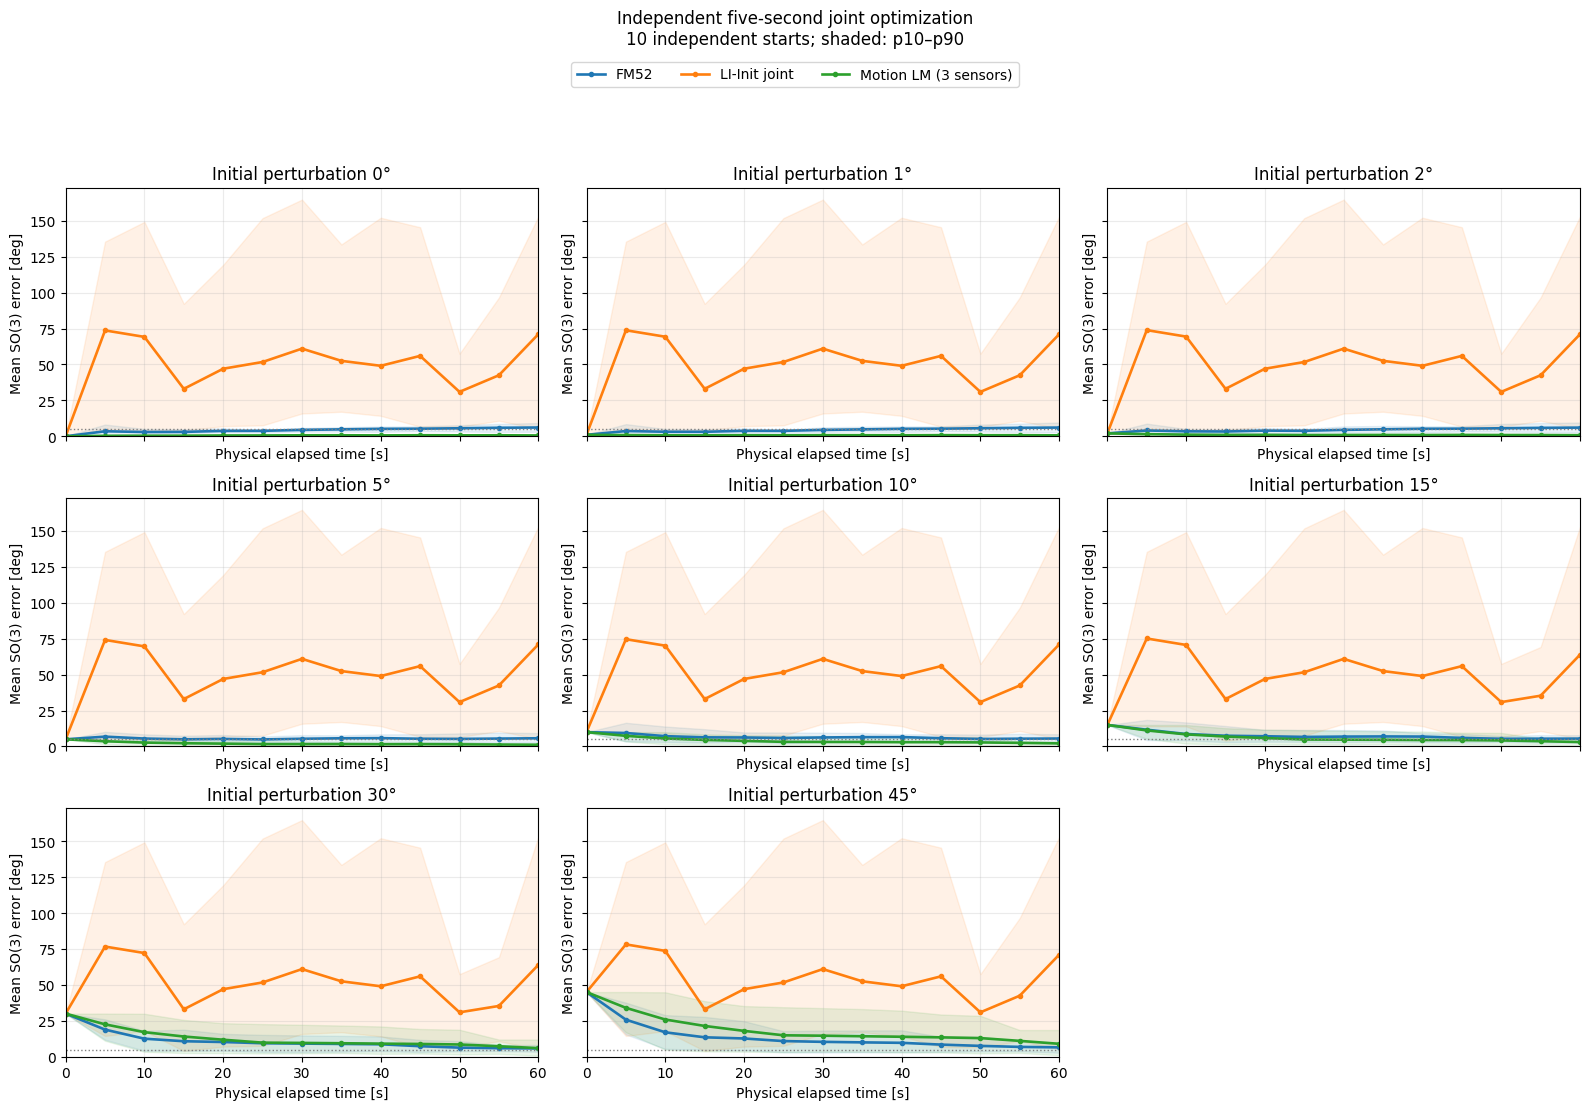

Saved /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/outputs/plots/motion_refinement_fm_liinit_kaist/5s_independent_joint_rotation_full.png


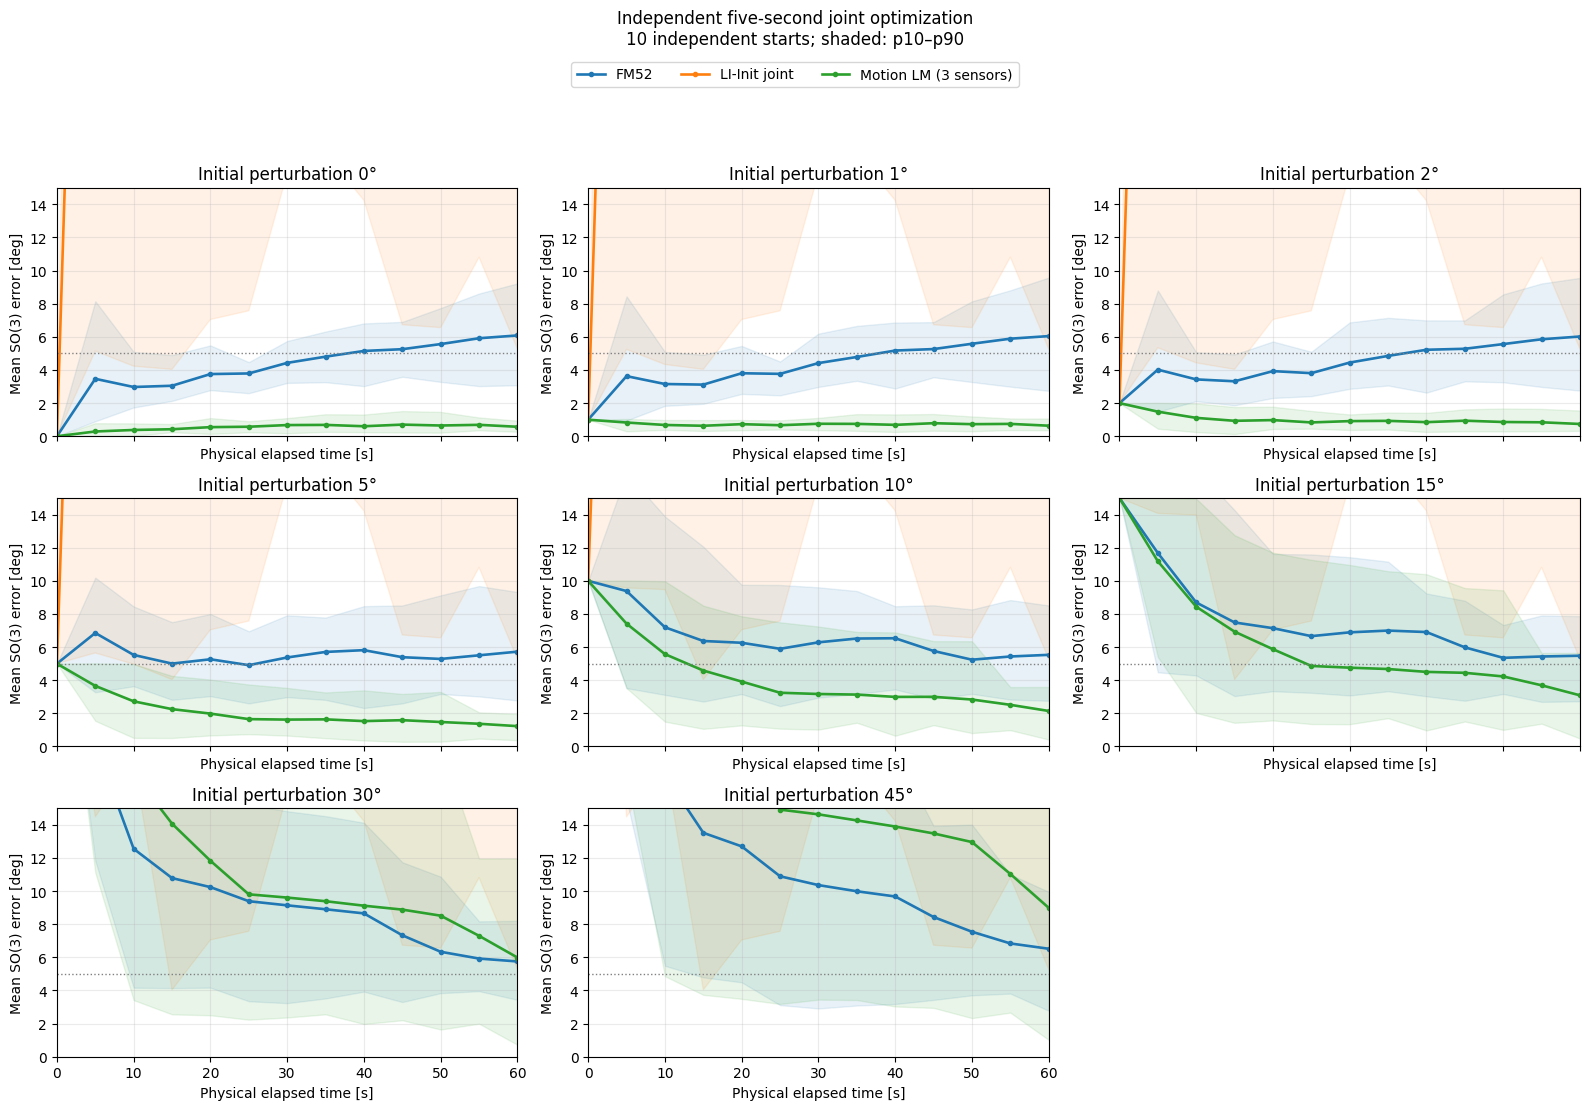

Saved /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/outputs/plots/motion_refinement_fm_liinit_kaist/5s_independent_joint_rotation_zoom15deg.png


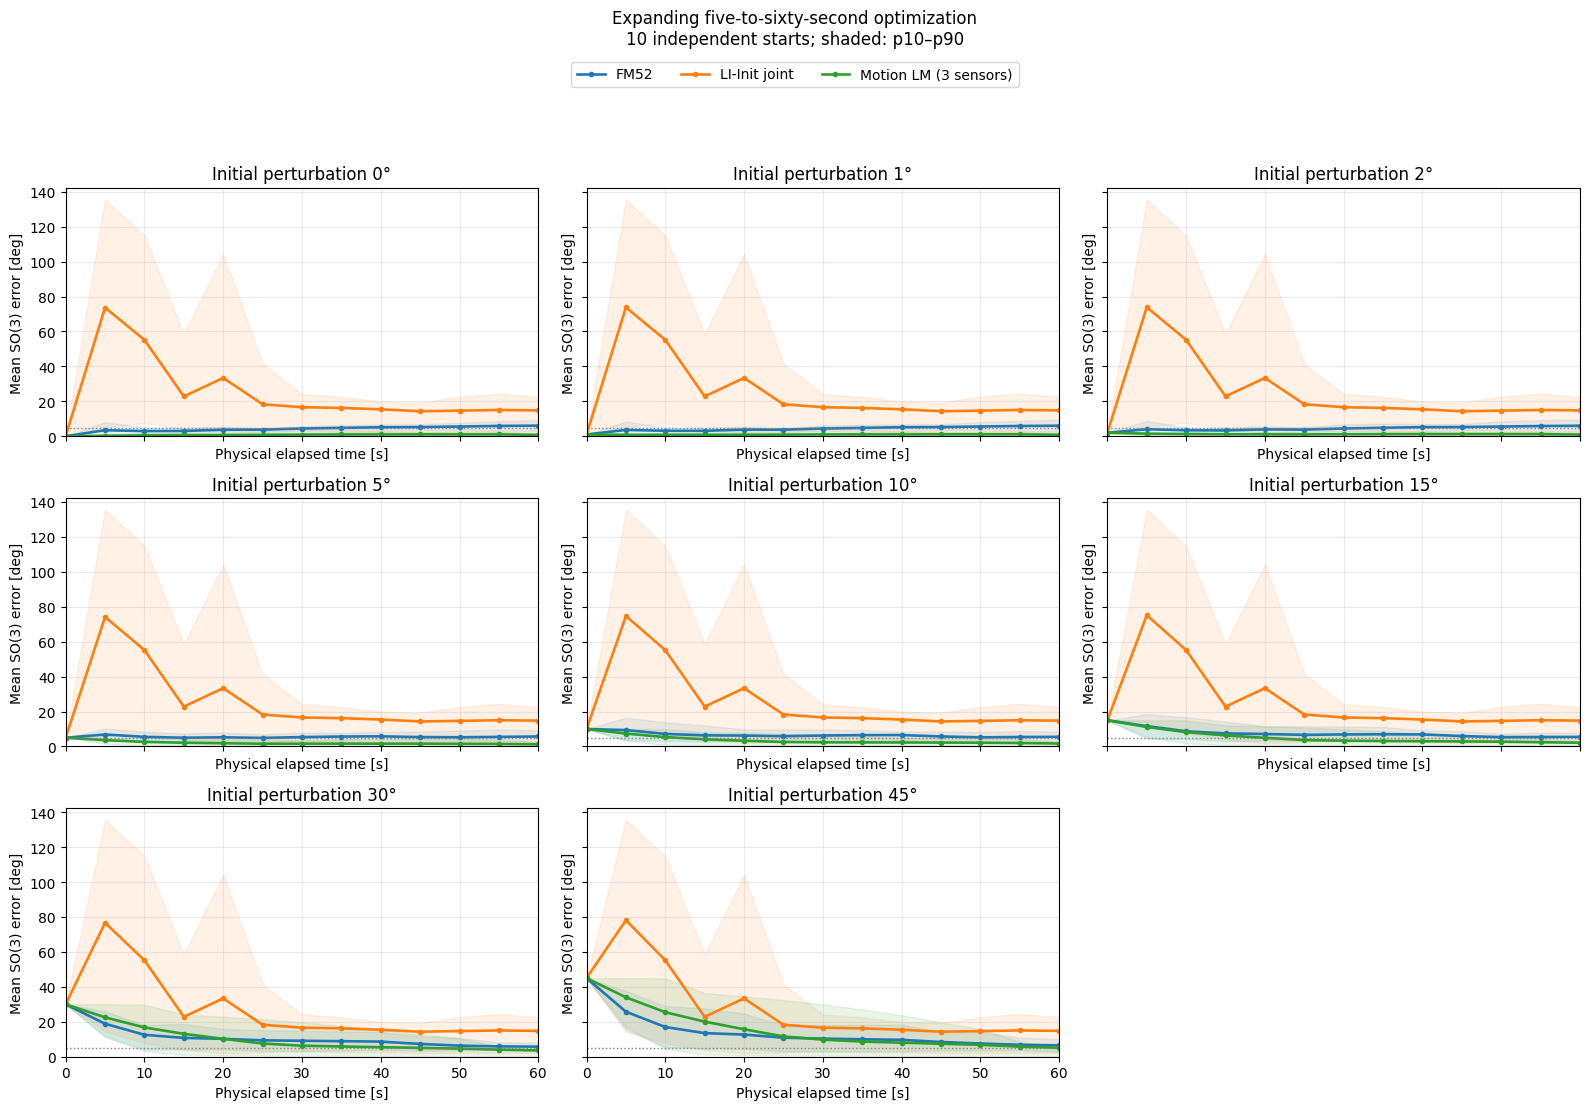

Saved /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/outputs/plots/motion_refinement_fm_liinit_kaist/cumulative_up_to_60s_joint_rotation_full.png


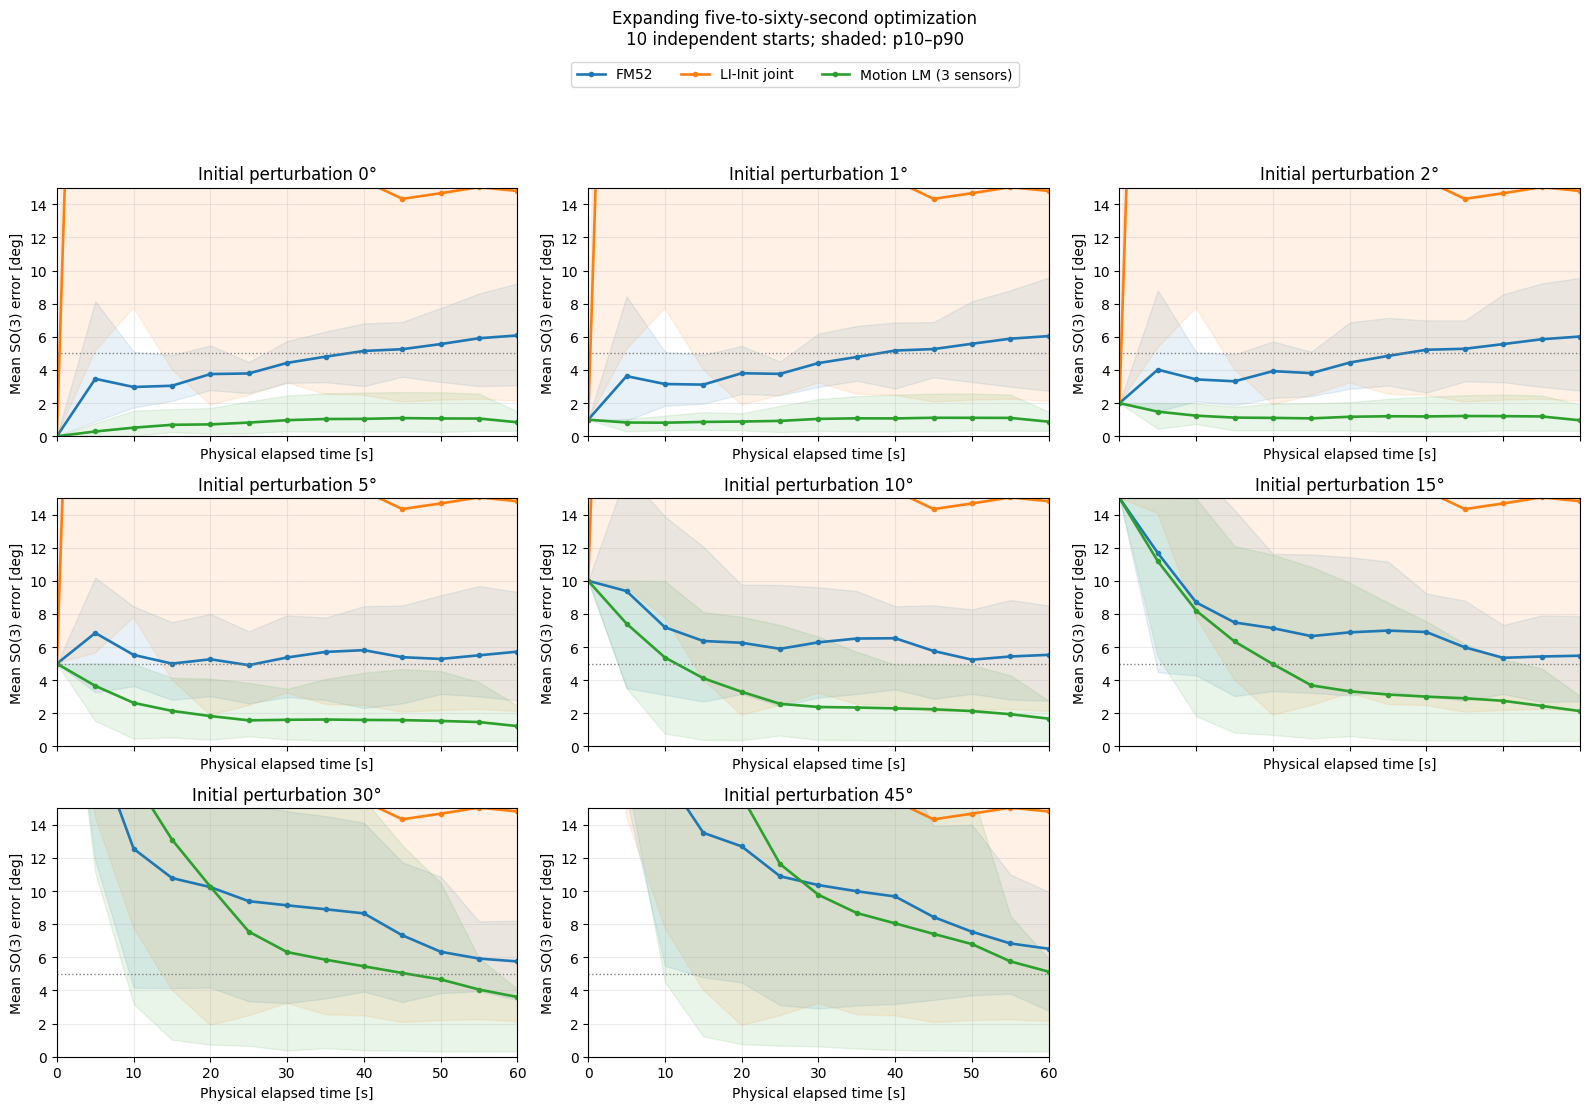

Saved /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/outputs/plots/motion_refinement_fm_liinit_kaist/cumulative_up_to_60s_joint_rotation_zoom15deg.png


In [13]:
def plot_angle_grid(mode, *, zoom_max=None):
    fig, axes = plt.subplots(int(np.ceil(len(ANGLES_DEG) / 3)), 3,
                             figsize=(16, 3.65 * int(np.ceil(len(ANGLES_DEG) / 3))),
                             sharex=True, sharey=zoom_max is None, squeeze=False)
    for ax, angle in zip(axes.flat, ANGLES_DEG):
        for method in METHODS:
            part = summary[(summary["mode"] == mode) & (summary.initial_deg == angle) & (summary.method == method)].sort_values("step")
            x = part.physical_elapsed_s.to_numpy()
            ax.plot(x, part.mean_deg, color=METHOD_COLORS[method], marker="o", markersize=3,
                    linewidth=1.9, label=method)
            ax.fill_between(x, part.q10_deg.to_numpy(), part.q90_deg.to_numpy(),
                            color=METHOD_COLORS[method], alpha=0.10)
        ax.axhline(5.0, linestyle=":", linewidth=1, color="gray")
        ax.set_title(f"Initial perturbation {angle:g}°")
        ax.set_xlim(0, ROLLOUT_S)
        ax.set_xticks(np.arange(0, ROLLOUT_S + 1, 10))
        ax.set_ylim(bottom=0, top=zoom_max)
        ax.set(xlabel="Physical elapsed time [s]", ylabel="Mean SO(3) error [deg]")
        ax.grid(alpha=0.25)
    for ax in axes.flat[len(ANGLES_DEG):]:
        ax.axis("off")
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.968), ncol=3)
    fig.suptitle(f"{MODE_TITLES[mode]}\n{NUM_STARTS} independent starts; shaded: p10–p90", y=1.01)
    fig.tight_layout(rect=(0, 0, 1, 0.93))
    suffix = "full" if zoom_max is None else f"zoom{zoom_max:g}deg"
    path = PLOTS_DIR / f"{mode}_rotation_{suffix}.png"
    fig.savefig(path, dpi=175, bbox_inches="tight")
    if SHOW_PLOTS: plt.show()
    else: plt.close(fig)
    print("Saved", path)

for mode in ACTIVE_MODES:
    plot_angle_grid(mode)
    plot_angle_grid(mode, zoom_max=15.0)


## 13. Solving latency: **per update**, cumulative time, and error-versus-cost

The plotted times are measured per fit, not theoretical FLOPs. FM includes preprocessing/tokenization and 16 integration steps on its selected device; LI-Init includes its coarse timing search and SciPy optimization; LM includes factor construction, pair alignment, numerical Jacobians, and damping trials. Dataset I/O/window slicing is excluded from all three. CPU and GPU timings describe this hardware and should not be interpreted as device-independent algorithmic speed. Invalid inputs have NaN solve latency, not 0 ms.

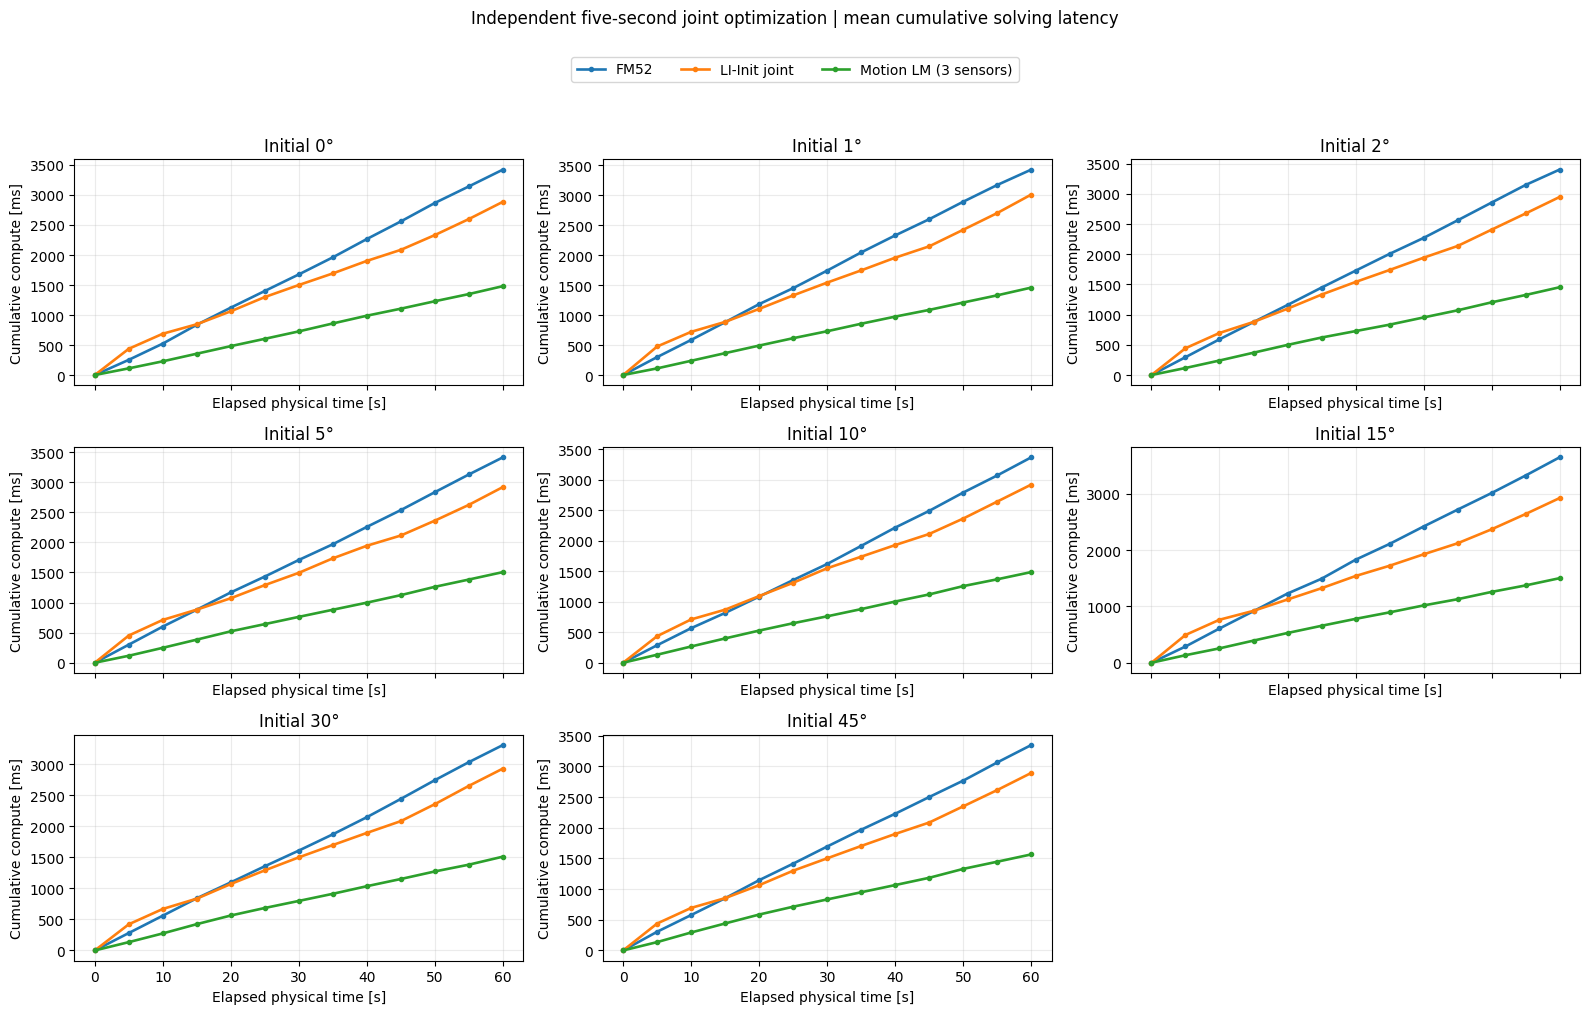

Saved /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/outputs/plots/motion_refinement_fm_liinit_kaist/5s_independent_joint_cumulative_runtime.png


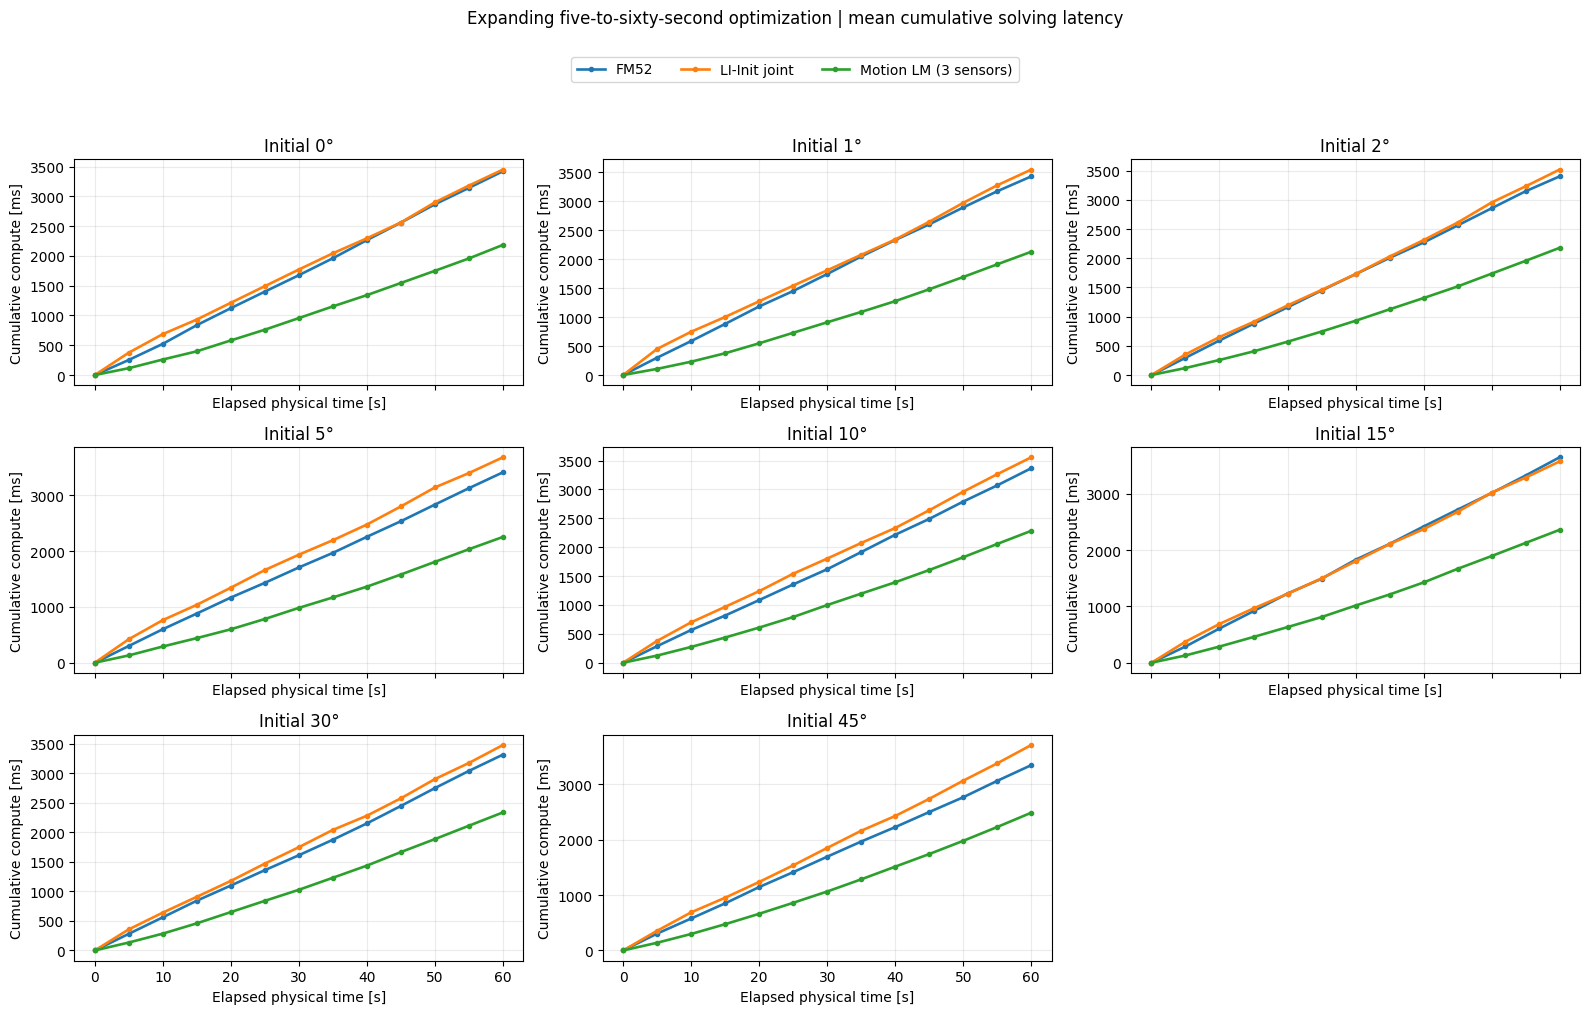

Saved /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/outputs/plots/motion_refinement_fm_liinit_kaist/cumulative_up_to_60s_joint_cumulative_runtime.png


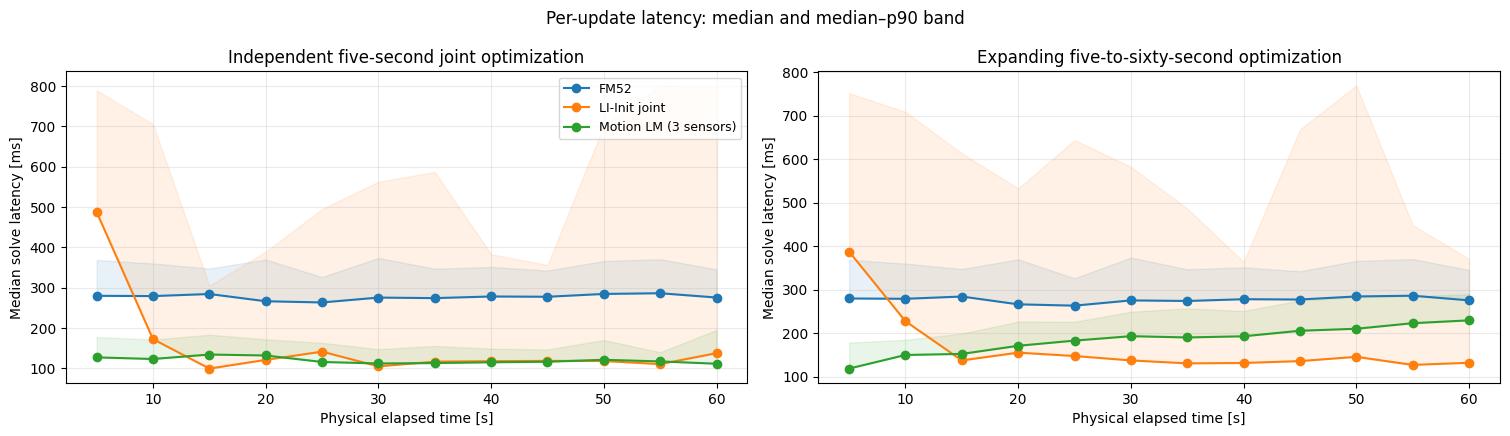

In [14]:
def plot_runtime_grid(mode):
    fig, axes = plt.subplots(int(np.ceil(len(ANGLES_DEG) / 3)), 3, figsize=(16, 10), sharex=True, squeeze=False)
    for ax, angle in zip(axes.flat, ANGLES_DEG):
        for method in METHODS:
            part = summary[(summary["mode"] == mode) & (summary.initial_deg == angle) & (summary.method == method)].sort_values("step")
            ax.plot(part.physical_elapsed_s, part.mean_cumulative_ms, color=METHOD_COLORS[method],
                    linewidth=1.9, marker="o", markersize=3, label=method)
        ax.set(title=f"Initial {angle:g}°", xlabel="Elapsed physical time [s]", ylabel="Cumulative compute [ms]")
        ax.grid(alpha=0.25)
    for ax in axes.flat[len(ANGLES_DEG):]: ax.axis("off")
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.969), ncol=3)
    fig.suptitle(MODE_TITLES[mode] + " | mean cumulative solving latency", y=1.01)
    fig.tight_layout(rect=(0, 0, 1, 0.93))
    path = PLOTS_DIR / f"{mode}_cumulative_runtime.png"
    fig.savefig(path, dpi=175, bbox_inches="tight")
    if SHOW_PLOTS: plt.show()
    else: plt.close(fig)
    print("Saved", path)

for mode in ACTIVE_MODES:
    plot_runtime_grid(mode)

fig, axes = plt.subplots(1, len(ACTIVE_MODES), figsize=(7.6 * len(ACTIVE_MODES), 4.4), squeeze=False)
for ax, mode in zip(axes.flat, ACTIVE_MODES):
    for method in METHODS:
        s = (rollout_df[(rollout_df["mode"] == mode) & (rollout_df.method == method) & (rollout_df.step > 0)]
             .groupby("step", as_index=False).agg(mean_ms=("elapsed_ms", "mean"), median_ms=("elapsed_ms", "median"), p90_ms=("elapsed_ms", q90)))
        ax.plot(s.step * WINDOW_S, s.median_ms, color=METHOD_COLORS[method], marker="o", label=method)
        ax.fill_between(s.step.to_numpy() * WINDOW_S, s.median_ms.to_numpy(), s.p90_ms.to_numpy(),
                        color=METHOD_COLORS[method], alpha=0.10)
    ax.set(title=MODE_TITLES[mode], xlabel="Physical elapsed time [s]", ylabel="Median solve latency [ms]")
    ax.grid(alpha=0.25)
axes.flat[0].legend(ncol=1, fontsize=9)
fig.suptitle("Per-update latency: median and median–p90 band")
fig.tight_layout()
fig.savefig(PLOTS_DIR / "per_update_latency.png", dpi=175, bbox_inches="tight")
if SHOW_PLOTS: plt.show()
else: plt.close(fig)


## 14. Accuracy, success rates, and latency tables

Success below a threshold is evaluated against nominal rig rotation; it is **not** numerical convergence. Report runtime both for all attempted fits and conditional on valid input. The area under the error-versus-physical-time curve measures rollout stability, including early degradation and recovery.

Endpoint metrics


,mode,method,initial_deg,n,mean_final_deg,median_final_deg,p90_final_deg,under_1deg,under_5deg,mean_compute_ms,median_compute_ms
0,5s_independent_joint,FM52,0.0,10,6.086,6.103,9.228,0.0,0.4,3423.087,3425.744
1,5s_independent_joint,FM52,1.0,10,6.047,6.080,9.579,0.0,0.4,3430.408,3265.719
2,5s_independent_joint,FM52,2.0,10,6.022,5.957,9.560,0.0,0.4,3403.433,3363.783
3,5s_independent_joint,FM52,5.0,10,5.725,4.862,9.327,0.0,0.5,3412.050,3373.168
4,5s_independent_joint,FM52,10.0,10,5.533,5.034,8.514,0.0,0.5,3367.432,3324.643
5,5s_independent_joint,FM52,15.0,10,5.479,5.696,7.870,0.0,0.4,3644.692,3510.603
6,5s_independent_joint,FM52,30.0,10,5.752,5.046,8.205,0.0,0.5,3312.754,3374.775
7,5s_independent_joint,FM52,45.0,10,6.518,5.944,9.954,0.0,0.4,3348.493,3220.213
8,5s_independent_joint,LI-Init joint,0.0,10,71.014,78.049,152.927,0.0,0.1,2886.782,2229.195
9,5s_independent_joint,LI-Init joint,1.0,10,71.024,78.050,152.928,0.0,0.1,3013.939,2080.095


Convergence and computation


,mode,method,initial_deg,mean_time_error_deg,median_first_under_5deg_s,final_under_5deg,mean_step_latency_ms,mean_total_compute_ms,accepted_fraction
0,5s_independent_joint,FM52,0.0,4.267,5.0,0.4,285.257,3423.087,1.000
1,5s_independent_joint,FM52,1.0,4.343,5.0,0.4,285.867,3430.408,1.000
2,5s_independent_joint,FM52,2.0,4.479,5.0,0.4,283.619,3403.433,1.000
3,5s_independent_joint,FM52,5.0,5.500,7.5,0.5,284.338,3412.050,1.000
4,5s_independent_joint,FM52,10.0,6.554,10.0,0.5,280.619,3367.432,1.000
5,5s_independent_joint,FM52,15.0,7.456,12.5,0.4,303.724,3644.692,1.000
6,5s_independent_joint,FM52,30.0,10.500,40.0,0.5,276.063,3312.754,1.000
7,5s_independent_joint,FM52,45.0,13.207,32.5,0.4,279.041,3348.493,1.000
8,5s_independent_joint,LI-Init joint,0.0,50.168,12.5,0.1,240.565,2886.782,0.958
9,5s_independent_joint,LI-Init joint,1.0,50.228,12.5,0.1,251.162,3013.939,0.958


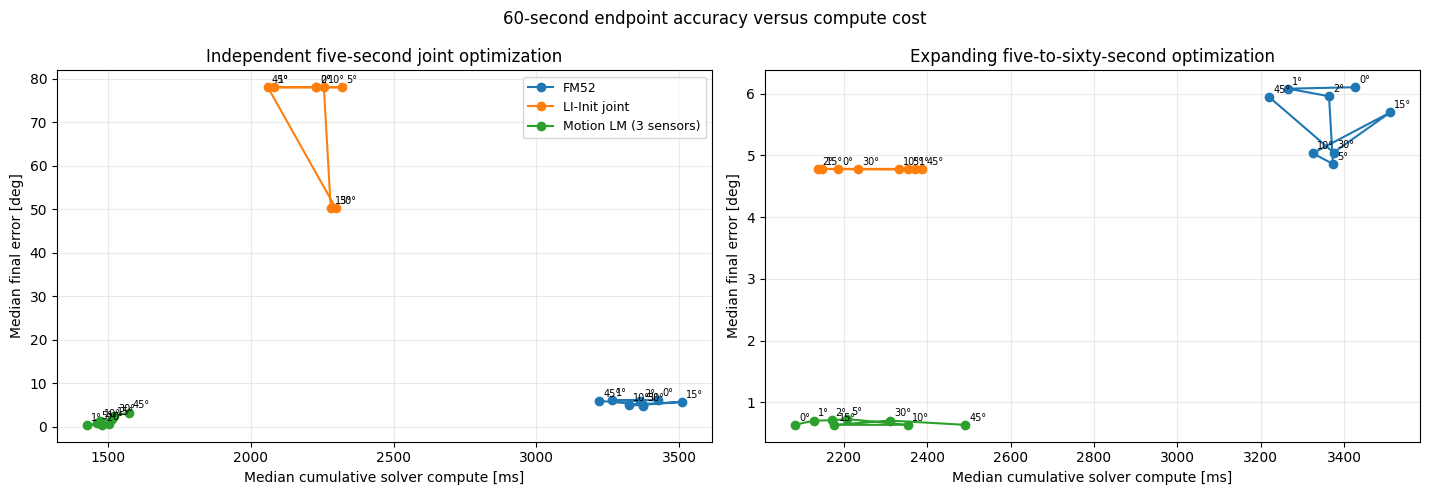

In [15]:
endpoints = rollout_df[rollout_df.step == STEPS].copy()
endpoints["under_1deg"] = endpoints.rotation_error_deg < 1.0
endpoints["under_5deg"] = endpoints.rotation_error_deg < 5.0
endpoint_summary = (endpoints.groupby(["mode", "method", "initial_deg"], as_index=False)
    .agg(n=("rotation_error_deg", "size"), mean_final_deg=("rotation_error_deg", "mean"),
         median_final_deg=("rotation_error_deg", "median"), p90_final_deg=("rotation_error_deg", q90),
         under_1deg=("under_1deg", "mean"), under_5deg=("under_5deg", "mean"),
         mean_compute_ms=("total_compute_ms", "mean"), median_compute_ms=("total_compute_ms", "median")))

run_stats = []
for (mode, method, start_id, axis_id, angle), part in rollout_df.groupby(
        ["mode", "method", "start_id", "axis_id", "initial_deg"], sort=False):
    part = part.sort_values("step")
    err = part.rotation_error_deg.to_numpy(dtype=float)
    elapsed = part.physical_elapsed_s.to_numpy(dtype=float)
    crossed = np.flatnonzero((err < 5.0) & (elapsed > 0))
    positive_steps = part[part.step > 0]
    run_stats.append(dict(mode=mode, method=method, start_id=start_id, axis_id=axis_id, initial_deg=angle,
                          time_mean_error_deg=float(trapezoid(err, elapsed) / ROLLOUT_S),
                          first_under_5deg_s=float(elapsed[crossed[0]]) if crossed.size else np.nan,
                          final_under_5deg=bool(err[-1] < 5.0),
                          mean_step_latency_ms=float(positive_steps.elapsed_ms.mean()),
                          total_compute_ms=float(part.total_compute_ms.iloc[-1]),
                          accepted_fraction=float(positive_steps.accepted.astype(float).mean())))
run_stats_df = pd.DataFrame(run_stats)
convergence_summary = (run_stats_df.groupby(["mode", "method", "initial_deg"], as_index=False)
    .agg(mean_time_error_deg=("time_mean_error_deg", "mean"),
         median_first_under_5deg_s=("first_under_5deg_s", "median"),
         final_under_5deg=("final_under_5deg", "mean"),
         mean_step_latency_ms=("mean_step_latency_ms", "mean"),
         mean_total_compute_ms=("total_compute_ms", "mean"),
         accepted_fraction=("accepted_fraction", "mean")))

print("Endpoint metrics")
display(endpoint_summary.round(3))
print("Convergence and computation")
display(convergence_summary.round(3))

endpoint_summary.to_csv(OUTPUT_DIR / "fm_liinit_lm_endpoints.csv", index=False)
run_stats_df.to_csv(OUTPUT_DIR / "fm_liinit_lm_run_stats.csv", index=False)
convergence_summary.to_csv(OUTPUT_DIR / "fm_liinit_lm_convergence.csv", index=False)

# Dedicated compute-vs-quality figure at 60s, one point per method and initial angle.
fig, axes = plt.subplots(1, len(ACTIVE_MODES), figsize=(7.2 * len(ACTIVE_MODES), 5.0), squeeze=False)
for ax, mode in zip(axes.flat, ACTIVE_MODES):
    for method in METHODS:
        s = endpoint_summary[(endpoint_summary["mode"] == mode) & (endpoint_summary["method"] == method)].sort_values("initial_deg")
        ax.plot(s.median_compute_ms, s.median_final_deg, marker="o", label=method, color=METHOD_COLORS[method])
        for row in s.itertuples():
            ax.annotate(f"{row.initial_deg:g}°", (row.median_compute_ms, row.median_final_deg), fontsize=7, xytext=(3, 3), textcoords="offset points")
    ax.set(xlabel="Median cumulative solver compute [ms]", ylabel="Median final error [deg]", title=MODE_TITLES[mode])
    ax.grid(alpha=0.25)
axes.flat[0].legend(fontsize=9)
fig.suptitle("60-second endpoint accuracy versus compute cost")
fig.tight_layout()
fig.savefig(PLOTS_DIR / "endpoint_error_vs_compute.png", dpi=175, bbox_inches="tight")
if SHOW_PLOTS: plt.show()
else: plt.close(fig)


## 15. Optional: LM iteration count ablation (1, 3, 5, 10)

**Default is 5 LM iterations**, enough for several bounded 12° local corrections. This short one-window diagnostic evaluates the same starts at each iteration count, with a **fresh identical prior** for every solve. It is intentionally **disabled by default** because it's extra work and using held-out Urban38/Urban39 to tune iterations would bias the final benchmark. Run it on a validation recording or treat the results as exploratory rather than as a test-set-selected hyperparameter.

To run: set `RUN_LM_ITERATION_ABLATION=True` in configuration, rerun this cell. It reports angle error versus latency (and accepted updates), **not** a 60-second sequential rollout. The full comparison above remains unchanged.

LM iteration ablation:   0%|          | 0/10 [00:00<?, ?it/s]

,max_iterations,initial_deg,median_error_deg,mean_error_deg,p90_error_deg,median_latency_ms,success_rate
0,1,0.0,0.093,0.277,0.769,61.588,1.0
1,1,5.0,4.704,3.680,5.016,55.170,1.0
2,1,15.0,14.191,11.377,15.017,54.155,1.0
3,1,30.0,28.480,25.581,30.025,58.200,1.0
4,1,45.0,43.165,40.514,45.030,57.341,1.0
5,3,0.0,0.098,0.289,0.789,113.422,1.0
6,3,5.0,4.696,3.659,5.017,105.662,1.0
7,3,15.0,14.167,11.184,15.019,117.722,1.0
8,3,30.0,28.415,22.548,30.028,105.599,1.0
9,3,45.0,42.756,34.379,45.034,111.437,1.0


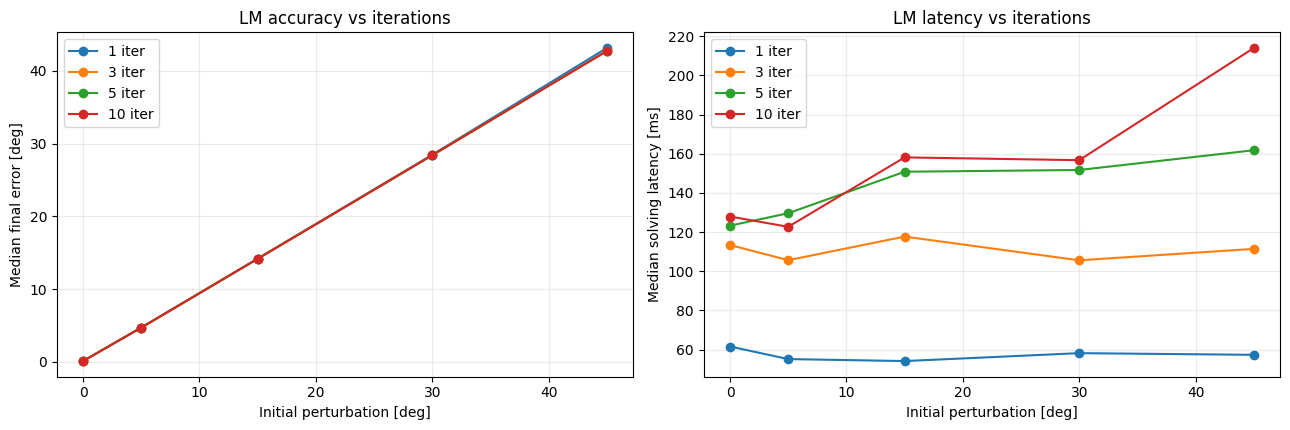

In [16]:
if RUN_LM_ITERATION_ABLATION:
    lm_ablation_rows = []
    tested_start_ids = list(range(min(LM_ABLATION_MAX_STARTS, NUM_STARTS)))
    first_mode = MODE_5S if MODE_5S in ACTIVE_MODES else MODE_60S
    for start_id in tqdm(tested_start_ids, desc="LM iteration ablation"):
        entry = rollouts[start_id]
        imu, lidar, right, right_error, left_error = numeric_windows[start_id, first_mode, 1]
        if right_error is not None or left_error is not None:
            continue
        axis = trial_axis(start_id, 0)
        for angle in LM_ABLATION_ANGLES_DEG:
            starting = make_initial_states(fm_windows[entry["indices"][0]], angle, axis)
            T_prior = T_I_L_nominal.copy()
            T_prior[:3, :3] = R_B_I.T @ np_array(starting[TARGET_KEY].transform[0, :3, :3])
            for iters in LM_ABLATION_ITERATIONS:
                cfg = replace(lm_config, max_iterations=int(iters))
                solver = MotionRefinementCalibrator(cfg)
                T_out, _, _, accepted, latency, status, iterations_done, accepted_iterations, rank, _ = lm_step_cached(
                    imu, lidar, right, T_prior.copy(), np.asarray(LM_INITIAL_GYRO_BIAS), LM_INITIAL_TIME_OFFSET_S, calibrator=solver)
                lm_ablation_rows.append(dict(start_id=start_id, initial_deg=angle, max_iterations=iters,
                                              accepted=accepted, iterations_done=iterations_done,
                                              accepted_iterations=accepted_iterations, observable_rank=rank,
                                              error_deg=rotation_error_B_L(R_B_I @ T_out[:3, :3]),
                                              latency_ms=latency, status=status))
    lm_ablation = pd.DataFrame(lm_ablation_rows)
    if lm_ablation.empty:
        print("No valid LM ablation cases")
    else:
        lm_ablation.to_csv(OUTPUT_DIR / "lm_iterations_ablation.csv", index=False)
        lm_ablation_summary = (lm_ablation.groupby(["max_iterations", "initial_deg"], as_index=False)
            .agg(median_error_deg=("error_deg", "median"), mean_error_deg=("error_deg", "mean"),
                 p90_error_deg=("error_deg", q90), median_latency_ms=("latency_ms", "median"),
                 success_rate=("accepted", "mean")))
        display(lm_ablation_summary.round(3))
        fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
        for n, part in lm_ablation_summary.groupby("max_iterations"):
            axes[0].plot(part.initial_deg, part.median_error_deg, marker="o", label=f"{n} iter")
            axes[1].plot(part.initial_deg, part.median_latency_ms, marker="o", label=f"{n} iter")
        axes[0].set(xlabel="Initial perturbation [deg]", ylabel="Median final error [deg]", title="LM accuracy vs iterations")
        axes[1].set(xlabel="Initial perturbation [deg]", ylabel="Median solving latency [ms]", title="LM latency vs iterations")
        for ax in axes: ax.grid(alpha=0.25); ax.legend()
        fig.tight_layout()
        fig.savefig(PLOTS_DIR / "lm_iterations_ablation.png", dpi=175)
        if SHOW_PLOTS: plt.show()
        else: plt.close(fig)
else:
    print("LM iteration ablation disabled; set RUN_LM_ITERATION_ABLATION=True for an exploratory validation sweep.")


## 16. Interpretation checklist

- **0° cases:** already-correct calibration should ideally remain close to 0°. FM/LM/LI-Init can drift when five-second data are weakly informative. Compare their **no-update** errors at 0° and positive angles before claiming refinement.
- **Fine angles:** compare 1°, 2°, 5°, 10° separately. A smaller endpoint error can still conceal poor intermediate rollout behavior; inspect AUC and p90 bands.
- **LM iterations:** five is a starting compromise, **not** proven optimal. The optional 1/3/5/10 ablation changes the solver's correction budget and latency; select using validation data.
- **Different nuisance states:** LI-Init fits gyro bias and temporal shift; LM holds both fixed by default. To compare the same nuisance freedoms, enable `LM_OPTIMIZE_GYRO_BIAS` and `LM_OPTIMIZE_TIME_OFFSET` and keep IMU context padding large enough. These settings alter numerical conditioning, so retain both versions as separate named benchmarks.
- **Additional anchor information:** LM and FM see two LiDARs; LI-Init does not. LM additionally uses nominal fixed lever arms and right-LiDAR transform; these are part of the experiment's assumed known rig, not a calibration derived from the current left-LiDAR measurements.
- **Lookahead:** numerical methods use 0.35-s future IMU context, LM additionally uses 0.20-s future right-LiDAR odometry for interpolation. The physical-time curves are therefore approximate time-indexed comparisons, not strictly online zero-lookahead latencies.
- **Latency scope:** FM is timed on CUDA (if available) and numerics on CPU; all are end-to-end algorithm calls with prepared windows, not identical-hardware operation counts. LM's numerical Jacobians can dominate runtime, especially for 60-second re-fits.
- **Failures and observability:** the `success` / `accepted` flag measures numerical fit status, not angular accuracy. Low-rank TSVD may preserve a good prior while adjusting only observable directions. Input preparation failures remain visible and do not claim 0-ms work.
- **Data split:** Urban38/Urban39 are held-out for this checkpoint. Do not tune prior sigma, factor noise, or iteration count on these tests if you want unbiased final numbers.
- **Potential next comparisons:** LM gyro-only (`use_lidar_pair="off"`), LM joint bias/timing, LI-Init with known synchronization, and a 5-second **no-update** prior. You can add these as separate ablations without changing the main three-line plot protocol.

In [17]:
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()
print("Comparison notebook finished; outputs:", OUTPUT_DIR, "plots:", PLOTS_DIR)


Comparison notebook finished; outputs: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/outputs/motion_refinement_fm_liinit_kaist plots: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/outputs/plots/motion_refinement_fm_liinit_kaist
